# Keeping Customers Before They Leave: A Data-Driven Retention Proposal for Company A
**GCI World 2026 September — Final Assignment (Course Project PoC)**  
**Author:** Islam Raad (`Islam-Raad`) — AI Engineering, University of Mosul

---

## 0. Overview & How to Run

### Purpose
This self-contained notebook implements the end-to-end analysis supporting our Proof-of-Concept (PoC) business proposal for **Company A**, an anonymous wireless telecommunications operator (~100,000 customers):
1. **Data Audit & Exploratory Data Analysis (EDA):** Structural checks, missingness patterns, documentation vs. data verification, and statistical robustness testing of lifecycle churn thresholds (~300-day handset age and months 10–12 tenure cliff).
2. **Leakage-Safe Preprocessing & Feature Engineering:** Domain-grounded behavioral, lifecycle, call-quality, and economic features.
3. **Predictive Modeling & Interpretation:** Stratified 5-fold cross-validation across baseline and boosted-tree models, held-out test evaluation, top-$k$ targeting lift, gain and permutation importance, partial dependence, and fairness checks.
4. **Realistic Business-Impact Model:** Label-shift re-basing from the 49.56% resampled dataset to realistic telecom churn priors (5%–10%), net value estimation in monetary units (MU), scenario analysis, break-even success rate ($s^*$), optimal targeting depth ($k^*$), and tornado sensitivity.

### Folder Structure & Auto-Detection
- The notebook automatically locates `Client.csv` and `Record.csv` by checking `./telecom/`, `../telecom/` (when run from `submission/`), and `/content/drive/MyDrive/Final Assignment/telecom/` (Google Colab).
- When run inside the project workspace, it writes summary metrics to `outputs/results.json`, tables to `outputs/tables/`, and 200-DPI `matplotlib` figures to `outputs/figures/`.

### Generative AI Disclosure
Generative AI tools (Claude and Google Antigravity / Gemini) were used as analytical and coding assistants during project development. All code was executed and verified against the raw dataset, all external market statistics were verified from primary sources, and the full methodology is documented and explained by the author.

> **So what:** Every figure and number in the 15-slide executive presentation is reproducibly generated from this single notebook with `random_state=42`.

---
## 1. Setup, Environment & Matplotlib Styling Helpers

In [1]:
import json
import os
import platform
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.font_manager as fm
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
from xgboost import XGBClassifier

try:
    import lightgbm as lgb
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

warnings.filterwarnings('ignore', category=FutureWarning)
NB_START_TIME = time.time()
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 120)

# Auto-detect DATA_DIR and OUTPUT_DIR (works from repo root, submission/, or Colab)
CANDIDATE_DATA_DIRS = [
    Path('./telecom'),
    Path('../telecom'),
    Path('/content/drive/MyDrive/Final Assignment/telecom'),
]
DATA_DIR = None
for cand in CANDIDATE_DATA_DIRS:
    if (cand / 'Client.csv').exists() and (cand / 'Record.csv').exists():
        DATA_DIR = cand.resolve()
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        'Could not locate telecom dataset. Expected Client.csv and Record.csv in one of: '
        + ', '.join(str(p) for p in CANDIDATE_DATA_DIRS)
    )

PROJECT_ROOT = DATA_DIR.parent
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
FIG_DIR = OUTPUT_DIR / 'figures'
TAB_DIR = OUTPUT_DIR / 'tables'
MOD_DIR = OUTPUT_DIR / 'models'
for d in (OUTPUT_DIR, FIG_DIR, TAB_DIR, MOD_DIR):
    d.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = OUTPUT_DIR / 'results.json'
if RESULTS_PATH.exists():
    RESULTS = json.loads(RESULTS_PATH.read_text(encoding='utf-8'))
else:
    RESULTS = {
        'data': {},
        'eda': {},
        'models': [],
        'final_model': {},
        'topk': [],
        'importance': {},
        'impact': {},
        'meta': {},
    }

# Font check & Matplotlib rcParams (PRD §10 — matplotlib only)
available_fonts = {f.name for f in fm.fontManager.ttflist}
ACTIVE_FONT = 'Open Sans' if 'Open Sans' in available_fonts else 'DejaVu Sans'

PALETTE = {
    'navy': '#0B1F3A',
    'churn': '#E4572E',     # Coral (risk / churn)
    'coral': '#E4572E',
    'blue': '#3B7DD8',
    'stayed': '#3B7DD8',    # Blue (stayed / baseline)
    'teal': '#0F8B8D',      # Teal (highlight / accent)
    'amber': '#F2A541',     # Amber (callout)
    'text': '#1F2933',      # Neutral dark text
    'slate': '#5B6B7B',     # Secondary text / arrows
    'grid': '#D9E0E7',      # Light horizontal grid
    'card': '#F5F7FA',      # Card / panel background
    'white': '#FFFFFF',
}

FIG_SIZES = {
    'full': (9.0, 3.6),
    'half': (4.4, 3.3),
    'wide_short': (9.0, 2.4),
    'square': (4.4, 4.0),
}

TEAL_CMAP = LinearSegmentedColormap.from_list(
    'white_teal', ['#FFFFFF', '#D5ECEC', '#6BBEC0', '#0F8B8D', '#084C4E']
)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Open Sans', 'DejaVu Sans'],
    'font.size': 11,
    'axes.labelsize': 11,
    'axes.labelcolor': PALETTE['text'],
    'axes.edgecolor': PALETTE['grid'],
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'xtick.color': PALETTE['slate'],
    'ytick.color': PALETTE['slate'],
    'legend.fontsize': 10,
    'legend.frameon': False,
    'lines.linewidth': 2.2,
    'lines.markersize': 5.5,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.dpi': 200,
    'savefig.facecolor': 'white',
})


def make_fig(size_key='full', nrows=1, ncols=1, **kwargs):
    """Create a matplotlib figure at exact slide placement size with constrained_layout."""
    figsize = FIG_SIZES.get(size_key, size_key)
    fig, axes = plt.subplots(
        nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, **kwargs
    )
    return fig, axes


def style_ax(ax, grid_axis='y', caption=None):
    """Apply clean executive styling (no top/right spines, subtle grid, optional n= caption)."""
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color(PALETTE['slate'])
    ax.spines['bottom'].set_color(PALETTE['slate'])
    if grid_axis in ('y', 'both'):
        ax.yaxis.grid(True, color=PALETTE['grid'], linewidth=0.8, linestyle='-')
        ax.set_axisbelow(True)
    if grid_axis in ('x', 'both'):
        ax.xaxis.grid(True, color=PALETTE['grid'], linewidth=0.8, linestyle='-')
        ax.set_axisbelow(True)
    if caption:
        ax.text(
            0.99, -0.18, caption, transform=ax.transAxes,
            ha='right', va='top', fontsize=9.5, color=PALETTE['slate']
        )
    return ax


def save_slide_fig(fig, filename):
    """Save figure at 200 DPI without bbox_inches='tight' so placed dimensions stay exact."""
    out_path = FIG_DIR / filename
    fig.savefig(out_path, dpi=200, facecolor='white')
    return out_path


create_fig = make_fig
save_fig = save_slide_fig


def save_results():
    """Persist RESULTS dictionary to outputs/results.json."""
    RESULTS_PATH.write_text(json.dumps(RESULTS, indent=2), encoding='utf-8')


RESULTS['meta'] = {
    'seed': SEED,
    'interpreter': sys.executable,
    'python_version': platform.python_version(),
    'active_font': ACTIVE_FONT,
    'versions': {
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'scikit-learn': sklearn.__version__,
        'xgboost': xgb.__version__,
        'matplotlib': matplotlib.__version__,
        'scipy': scipy.__version__,
        'joblib': joblib.__version__,
        'lightgbm': lgb.__version__ if HAS_LIGHTGBM else None,
    },
}
save_results()
print(f'DATA_DIR: {DATA_DIR}')
print(f'Active font: {ACTIVE_FONT}')
print('Versions:', json.dumps(RESULTS['meta']['versions'], indent=2))

DATA_DIR: /home/islam-raad/Projects/Final Assignment/telecom
Active font: DejaVu Sans
Versions: {
  "pandas": "3.0.2",
  "numpy": "2.4.4",
  "scikit-learn": "1.8.0",
  "xgboost": "3.4.1",
  "matplotlib": "3.10.8",
  "scipy": "1.17.1",
  "joblib": "1.5.3",
  "lightgbm": "4.7.0"
}


> **So what:** Our environment, random seed (`42`), data paths, and executive `matplotlib` design system are locked in, ensuring every chart and metric is reproducible.

---
## 2. Load & Merge Dataset

Company A's dataset is provided as two customer-level tables in `telecom/`:
- `Client.csv`: 100,000 rows × 50 columns (`Customer_ID` + 49 demographic, household, handset, and lifetime summary features; 21 `object` and 28 numeric columns).
- `Record.csv`: 100,000 rows × 51 columns (`Customer_ID` + 49 numeric monthly usage, billing, call-quality, and customer-care features + the binary target `churn`). Note that `months` (service tenure) resides in `Record.csv`.

In [2]:
client_path = DATA_DIR / 'Client.csv'
record_path = DATA_DIR / 'Record.csv'

client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(f'Client shape: {client.shape}')
print(f'Record shape: {record.shape}')

# Strict schema & key assertions (T0.5)
assert client.shape == (100000, 50), f'Unexpected Client shape: {client.shape}'
assert record.shape == (100000, 51), f'Unexpected Record shape: {record.shape}'
assert 'Customer_ID' in client.columns and 'Customer_ID' in record.columns
assert client['Customer_ID'].is_unique, 'Client Customer_ID is not unique'
assert record['Customer_ID'].is_unique, 'Record Customer_ID is not unique'
assert set(client['Customer_ID']) == set(record['Customer_ID']), 'Customer_ID sets do not match'
assert (client['Customer_ID'].values == record['Customer_ID'].values).all(), 'Customer_ID ordering differs'

# 1-to-1 inner merge on Customer_ID
df = record.merge(client, on='Customer_ID', how='inner', validate='one_to_one')
assert df.shape == (100000, 100), f'Unexpected merged shape: {df.shape}'

print(f'Merged shape: {df.shape}')
print(f'Customer_ID range: {int(df["Customer_ID"].min())} to {int(df["Customer_ID"].max())} (unique: {df["Customer_ID"].nunique()})')
print(f'Tenure (months) in Record.csv: min={int(df["months"].min())}, median={float(df["months"].median()):.1f}, max={int(df["months"].max())}')
print('\nAll 100 columns in merged DataFrame (df.columns):')
print(list(df.columns))

RESULTS['data'].update({
    'n_rows': int(df.shape[0]),
    'n_cols': int(df.shape[1]),
    'n_features_raw': int(df.shape[1] - 2),
    'client_shape': list(client.shape),
    'record_shape': list(record.shape),
    'id_min': int(df['Customer_ID'].min()),
    'id_max': int(df['Customer_ID'].max()),
    'months_min': int(df['months'].min()),
    'months_median': float(df['months'].median()),
    'months_max': int(df['months'].max()),
})
save_results()

Client shape: (100000, 50)
Record shape: (100000, 51)
Merged shape: (100000, 100)
Customer_ID range: 1000001 to 1100000 (unique: 100000)
Tenure (months) in Record.csv: min=6, median=16.0, max=61

All 100 columns in merged DataFrame (df.columns):
['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'threeway_Mean', 'mou_cvce_Mean', 'mou_cdat_Mean', 'mou_rvce_Mean', 'owylis_vce_Mean', 'mouowylisv_Mean', 'iwylis_vce_Mean', 'mouiwylisv_Mean', 'peak_vce_Mean', 'peak_dat_Mean', 'mou_peav_Mean', 'mou_pead_Mean', 'opk_vce_Mean', 'opk_dat_Mean', 'mou_opkv_Mean', 'mou_opkd_Mean', 'drop_blk_Mean', 'attempt_Mean', 'complete_Mean', 'cal

> **So what:** `Client.csv` (100,000 × 50) and `Record.csv` (100,000 × 51) join 1-to-1 on `Customer_ID` (`1000001`–`1100000`) with zero orphan or duplicate records, producing a 100,000 × 100 master table (`98` raw features + `Customer_ID` + `churn`) where every customer has at least 6 months of tenure.

---
## 3. Data Audit & Quality Assessment

### 3.1 Structure, Data Types, Memory & Duplicate Checks (T1.1)
We audit the merged 100,000 × 100 table (`df`) for column data types (`float64`, `int64`, `object`/`str`), memory footprint, full-row duplicates, feature-only duplicates (excluding `Customer_ID`), and `Customer_ID` continuity.

In [3]:
# Note: pandas 3.0+ may represent text columns as 'str' or 'object'; count both text vs numeric types cleanly
raw_dtypes = df.dtypes.astype(str).value_counts().to_dict()
n_float64 = int((df.dtypes == 'float64').sum())
n_int64 = int((df.dtypes == 'int64').sum())
n_text = int(df.shape[1] - n_float64 - n_int64)
text_cols = [c for c in df.columns if df[c].dtype not in ('float64', 'int64')]
float_cols = [c for c in df.columns if df[c].dtype == 'float64']
int_cols = [c for c in df.columns if df[c].dtype == 'int64']

mem_mb = float(df.memory_usage(deep=True).sum() / (1024 ** 2))
n_dup_rows = int(df.duplicated().sum())
n_dup_without_id = int(df.drop(columns=['Customer_ID']).duplicated().sum())
id_expected = np.arange(1000001, 1100001)
id_exact_seq = bool(np.array_equal(df['Customer_ID'].values, id_expected))

assert n_float64 == 69, f'Expected 69 float64 cols, got {n_float64}'
assert n_int64 == 10, f'Expected 10 int64 cols, got {n_int64}'
assert n_text == 21, f'Expected 21 text/object cols, got {n_text}'
assert n_dup_rows == 0 and n_dup_without_id == 0
assert id_exact_seq

print(f'Dtype summary: float64={n_float64}, int64={n_int64}, object/string={n_text} (raw pandas dtypes: {raw_dtypes})')
print(f'Deep memory footprint: {mem_mb:.2f} MB')
print(f'Duplicate full rows: {n_dup_rows} | Duplicate feature rows (excl. Customer_ID): {n_dup_without_id}')
print(f'Customer_ID exact sequential 1000001..1100000: {id_exact_seq}')
print(f'int64 columns ({len(int_cols)}): {int_cols}')
print(f'Text/categorical columns ({len(text_cols)}): {text_cols}')

RESULTS['data']['dtypes'] = {
    'float64': n_float64,
    'int64': n_int64,
    'object': n_text,
    'int64_cols': int_cols,
    'object_cols': text_cols,
}
RESULTS['data']['memory_mb'] = round(mem_mb, 2)
RESULTS['data']['duplicate_rows'] = n_dup_rows
RESULTS['data']['duplicate_feature_rows'] = n_dup_without_id
RESULTS['data']['id_sequential_1000001_1100000'] = id_exact_seq
save_results()

Dtype summary: float64=69, int64=10, object/string=21 (raw pandas dtypes: {'float64': 69, 'str': 21, 'int64': 10})
Deep memory footprint: 158.88 MB
Duplicate full rows: 0 | Duplicate feature rows (excl. Customer_ID): 0
Customer_ID exact sequential 1000001..1100000: True
int64 columns (10): ['churn', 'months', 'Customer_ID', 'uniqsubs', 'actvsubs', 'totcalls', 'adjqty', 'avg3mou', 'avg3qty', 'avg3rev']
Text/categorical columns (21): ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']


> **So what:** The merged dataset has `69` `float64`, `10` `int64` (including `Customer_ID`, `churn`, `months`, household subscriber and handset counts), and `21` categorical text columns (all from `Client.csv`), with zero duplicate records and sequential IDs `1,000,001`–`1,100,000`.

### 3.2 Missing Values, Co-Missing Blocks & Churn-When-Missing Signal (T1.2)
We audit all columns with missing values, verify whether household/demographic columns are missing on the exact same customer records, and compare the churn rate when a column is missing vs. present.

In [4]:
# Compute full missingness table with churn-when-missing vs churn-when-present (T1.2)
missing_rows = []
base_churn = float(df['churn'].mean())

for col in df.columns:
    n_miss = int(df[col].isna().sum())
    if n_miss > 0:
        pct_miss = 100.0 * n_miss / len(df)
        c_miss = float(df.loc[df[col].isna(), 'churn'].mean())
        c_pres = float(df.loc[df[col].notna(), 'churn'].mean())
        missing_rows.append({
            'column': col,
            'source_table': 'Client' if col in client.columns else 'Record',
            'dtype': 'object' if df[col].dtype not in ('float64', 'int64') else str(df[col].dtype),
            'n_missing': n_miss,
            'pct_missing': round(pct_miss, 2),
            'churn_when_missing': round(100.0 * c_miss, 2),
            'churn_when_present': round(100.0 * c_pres, 2),
            'churn_diff_pp': round(100.0 * (c_miss - c_pres), 2),
        })

missing_df = pd.DataFrame(missing_rows).sort_values('n_missing', ascending=False).reset_index(drop=True)
print(f'Total columns with >=1 missing value: {len(missing_df)} of {df.shape[1]}')
print('\nFull Missingness Table (all columns with missing values):')
print(missing_df.to_string(index=False))

# Check the 1,732-row co-missing demographic block
demo_block_cols = [c for c in missing_df.loc[missing_df['n_missing'] == 1732, 'column']]
first_mask = df[demo_block_cols[0]].isna()
exact_same_rows = all((df[c].isna() == first_mask).all() for c in demo_block_cols)
demo_block_churn = float(df.loc[first_mask, 'churn'].mean())
print(f'\nCo-missing demographic block ({len(demo_block_cols)} cols, n={int(first_mask.sum())}): {demo_block_cols}')
print(f'Exact same 1,732 rows across all {len(demo_block_cols)} columns: {exact_same_rows} | Block churn rate: {100*demo_block_churn:.2f}%')

# Check high-signal missingness in change_mou / change_rev and monthly usage/billing block
chg_mask = df['change_mou'].isna()
chg_same = bool((df['change_mou'].isna() == df['change_rev'].isna()).all())
chg_churn = float(df.loc[chg_mask, 'churn'].mean())
print(f'Missing change_mou/change_rev: n={int(chg_mask.sum())} ({100*chg_mask.mean():.2f}%), identical rows={chg_same}, churn={100*chg_churn:.2f}% (vs {100*base_churn:.2f}% overall)')

# Plot top 20 missing columns + churn-when-missing callouts (fig_04_missing.png)
top20 = missing_df.head(20).iloc[::-1]  # reverse so highest is at top

fig, ax = plt.subplots(figsize=(4.4, 3.3), constrained_layout=True)
colors = [
    '#E4572E' if abs(r['churn_diff_pp']) >= 5.0 else '#0F8B8D' if r['pct_missing'] >= 20.0 else '#3B7DD8'
    for _, r in top20.iterrows()
]
bars = ax.barh(top20['column'], top20['pct_missing'], color=colors, height=0.72)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#5B6B7B')
ax.spines['bottom'].set_color('#5B6B7B')
ax.xaxis.grid(True, color='#D9E0E7', linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel('Missing values (% of 100,000 customers)', fontsize=10.5, color='#1F2933')
ax.set_xlim(0, 58)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.tick_params(axis='y', labelsize=9.5)
ax.tick_params(axis='x', labelsize=9.5)

for bar, (_, r) in zip(bars, top20.iterrows()):
    w = bar.get_width()
    label = f"{w:.1f}%"
    ax.text(w + 0.8, bar.get_y() + bar.get_height()/2, label, va='center', ha='left', fontsize=8.5, color='#1F2933')

ax.text(
    0.98, 0.06,
    'Note: missing change_mou (0.9%)\nhas 76.1% churn (signal!)',
    transform=ax.transAxes, ha='right', va='bottom', fontsize=9,
    color='#1F2933',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#F5F7FA', edgecolor='#E4572E', linewidth=1.0)
)

fig_path = FIG_DIR / 'fig_04_missing.png'
fig.savefig(fig_path, dpi=200, facecolor='white')
plt.close(fig)
print(f'Saved {fig_path}')

RESULTS['data']['missing_summary'] = {
    'n_cols_with_missing': int(len(missing_df)),
    'co_missing_demo_block_n': int(first_mask.sum()),
    'co_missing_demo_block_pct': round(100.0 * float(first_mask.mean()), 2),
    'co_missing_demo_block_cols': demo_block_cols,
    'co_missing_demo_block_exact_match': exact_same_rows,
    'co_missing_demo_block_churn_pct': round(100.0 * demo_block_churn, 2),
    'missing_change_mou_n': int(chg_mask.sum()),
    'missing_change_mou_pct': round(100.0 * float(chg_mask.mean()), 2),
    'missing_change_mou_churn_pct': round(100.0 * chg_churn, 2),
}
RESULTS['data']['missing_top'] = missing_df.head(20).to_dict(orient='records')
RESULTS['data']['missing_all'] = missing_df.to_dict(orient='records')
save_results()

Total columns with >=1 missing value: 43 of 100

Full Missingness Table (all columns with missing values):
          column source_table   dtype  n_missing  pct_missing  churn_when_missing  churn_when_present  churn_diff_pp
        numbcars       Client float64      49366        49.37               50.23               48.91           1.33
        dwllsize       Client  object      38308        38.31               51.03               48.65           2.39
        HHstatin       Client  object      37923        37.92               50.99               48.69           2.30
         ownrent       Client  object      33706        33.71               51.03               48.82           2.21
        dwlltype       Client  object      31909        31.91               51.16               48.81           2.35
             lor       Client float64      30190        30.19               51.36               48.79           2.57
          income       Client float64      25436        25.44             

Saved /home/islam-raad/Projects/Final Assignment/outputs/figures/fig_04_missing.png


> **So what:** Missingness is structured, not random: `43` columns have missing values (led by `numbcars` at `49.37%` and `dwllsize` at `38.31%`), `11` demographic fields are missing on the exact same `1,732` customers (`47.86%` churn), and the `891` customers missing `change_mou`/`change_rev` (`0.89%`) churn at **`76.09%`** vs. `49.56%` overall—proving that missingness flags carry predictive signal and must be preserved.

### 3.3 Negative & Impossible Values Audit + Explanation of `np.log1p` Warnings (T1.3)
We scan every numeric column for negative values, separate legitimate signed deltas (`change_mou`, `change_rev`) from anomalous negative values in non-negative quantities (`eqpdays`, `totmrc_Mean`, `rev_Mean`, `avg6rev`, `ovrrev_Mean`), and explain why `tutorial.ipynb` raised `RuntimeWarning` during `np.log1p`.

In [5]:
# Audit negative and impossible values across all numeric columns (T1.3)
num_cols = [c for c in df.columns if df[c].dtype in ('float64', 'int64') and c not in ('Customer_ID', 'churn')]
neg_rows = []
for col in num_cols:
    s = df[col].dropna()
    n_neg = int((s < 0).sum())
    if n_neg > 0:
        n_le_minus1 = int((s <= -1).sum())
        c_neg = float(df.loc[df[col] < 0, 'churn'].mean())
        neg_rows.append({
            'column': col,
            'n_negative': n_neg,
            'pct_negative': round(100.0 * n_neg / len(df), 3),
            'n_le_minus1': n_le_minus1,
            'min_val': round(float(s.min()), 2),
            'p50_val': round(float(s.median()), 2),
            'max_val': round(float(s.max()), 2),
            'churn_when_neg_pct': round(100.0 * c_neg, 2),
        })

neg_df = pd.DataFrame(neg_rows).sort_values('n_negative', ascending=False).reset_index(drop=True)
print('Columns with negative values:')
print(neg_df.to_string(index=False))

# Check mou_Mean specifically (confirm 0 negatives)
print(f'\nmou_Mean min={df["mou_Mean"].min():.2f}, negatives={(df["mou_Mean"] < 0).sum()}')

# Explain tutorial.ipynb Cell 29 np.log1p RuntimeWarnings
tut_log_cols = ['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'eqpdays']
print('\nWhy tutorial.ipynb Cell 29 raised RuntimeWarnings in np.log1p(x):')
for col in tut_log_cols:
    s = df[col].dropna()
    n_eq_m1 = int((s == -1).sum())
    n_lt_m1 = int((s < -1).sum())
    print(f'  {col:12s}: min={s.min():8.2f} | x == -1 (log1p -> -inf, divide-by-zero warning): {n_eq_m1:3d} | x < -1 (log1p -> NaN, invalid-value warning): {n_lt_m1:3d}')

RESULTS['data']['negatives'] = {
    r['column']: {
        'n_negative': int(r['n_negative']),
        'pct_negative': float(r['pct_negative']),
        'n_le_minus1': int(r['n_le_minus1']),
        'min_val': float(r['min_val']),
        'churn_when_neg_pct': float(r['churn_when_neg_pct']),
    }
    for _, r in neg_df.iterrows()
}
save_results()

Columns with negative values:
     column  n_negative  pct_negative  n_le_minus1  min_val  p50_val  max_val  churn_when_neg_pct
 change_rev       56150        56.150        41744 -1107.74    -0.32  9963.66               49.39
 change_mou       53651        53.651        52974 -3875.00    -6.25 31219.25               51.20
    eqpdays         133         0.133          133    -5.00   342.00  1823.00               35.34
totmrc_Mean          23         0.023           14   -26.91    44.99   409.99               47.83
   rev_Mean           5         0.005            4    -6.17    48.20  3843.26               40.00
    avg6rev           3         0.003            3    -2.00    50.00   866.00               66.67

mou_Mean min=0.00, negatives=0

Why tutorial.ipynb Cell 29 raised RuntimeWarnings in np.log1p(x):
  rev_Mean    : min=   -6.17 | x == -1 (log1p -> -inf, divide-by-zero warning):   0 | x < -1 (log1p -> NaN, invalid-value warning):   4
  mou_Mean    : min=    0.00 | x == -1 (log1p -> 

> **So what:** Aside from `change_mou` (`53,651` negatives) and `change_rev` (`56,150` negatives)—which are signed changes relative to the 3-month baseline—four columns have anomalous negatives: `eqpdays` (`133` rows, min `-5.0`, `35.34%` churn, likely pending/pre-activated handset swaps), `totmrc_Mean` (`23` rows, min `-26.91`), `rev_Mean` (`5` rows, min `-6.17`), and `avg6rev` (`3` rows, min `-2.0`, likely billing credits/adjustments). Because `np.log1p(x) = ln(1+x)` is undefined for `x < -1` (`NaN`) and `-inf` at `x = -1`, calling `np.log1p` directly on `eqpdays`, `totmrc_Mean`, and `rev_Mean` in `tutorial.ipynb` triggered `RuntimeWarning`.

### 3.4 Outliers, Heavy Right-Tail Skewness & Discrete Tiers (T1.4)
We compute percentiles (`p1`, `p50`, `p99`, `max`) and skewness across all 77 numeric features to identify extreme right-tail distributions (`uniqsubs`, `totcalls`, `totmou`, `rev_Mean`, `mou_Mean`) and discrete pricing tiers (`hnd_price`).

In [6]:
# Compute p1, p50, p99, max, and skewness for numeric columns (T1.4)
num_cols = [c for c in df.columns if df[c].dtype in ('float64', 'int64') and c not in ('Customer_ID', 'churn')]
outlier_rows = []
for col in num_cols:
    s = df[col].dropna()
    p1, p50, p99 = np.percentile(s, [1, 50, 99])
    mx = float(s.max())
    mn = float(s.min())
    sk = float(s.skew())
    ratio = mx / p99 if p99 > 0 else np.nan
    outlier_rows.append({
        'column': col,
        'min': round(mn, 2),
        'p1': round(float(p1), 2),
        'p50': round(float(p50), 2),
        'p99': round(float(p99), 2),
        'max': round(mx, 2),
        'max_over_p99': round(float(ratio), 2) if not np.isnan(ratio) else None,
        'skew': round(sk, 2),
    })

outlier_df = pd.DataFrame(outlier_rows).sort_values('skew', ascending=False).reset_index(drop=True)
print('Top 20 Most Right-Skewed Numeric Columns (p1 / p50 / p99 / max / skew):')
print(outlier_df.head(20).to_string(index=False))

focus_cols = ['uniqsubs', 'actvsubs', 'totcalls', 'totmou', 'totrev', 'rev_Mean', 'mou_Mean', 'totmrc_Mean', 'eqpdays', 'months', 'hnd_price']
print('\nKey Operational & Extreme Columns Summary:')
print(outlier_df[outlier_df['column'].isin(focus_cols)].to_string(index=False))

# Detailed checks on uniqsubs and hnd_price
n_uniq_gt6 = int((df['uniqsubs'] > 6).sum())
n_uniq_gt10 = int((df['uniqsubs'] > 10).sum())
hnd_tiers = sorted(df['hnd_price'].dropna().unique().tolist())
print(f'\nuniqsubs > 6: {n_uniq_gt6} customers | uniqsubs > 10: {n_uniq_gt10} customers (max={int(df["uniqsubs"].max())},likely enterprise/multi-line accounts)')
print(f'hnd_price has {len(hnd_tiers)} discrete price tiers: {[round(x, 2) for x in hnd_tiers]}')

RESULTS['data']['outliers_focus'] = outlier_df[outlier_df['column'].isin(focus_cols)].to_dict(orient='records')
RESULTS['data']['outliers_top_skew'] = outlier_df.head(20).to_dict(orient='records')
RESULTS['data']['hnd_price_n_tiers'] = len(hnd_tiers)
RESULTS['data']['uniqsubs_gt_10_n'] = n_uniq_gt10
save_results()

Top 20 Most Right-Skewed Numeric Columns (p1 / p50 / p99 / max / skew):
       column      min      p1   p50    p99      max  max_over_p99   skew
blck_dat_Mean     0.00    0.00  0.00   0.33   413.33       1240.00 224.60
    roam_Mean     0.00    0.00  0.00  22.41  3685.20        164.45 168.81
recv_sms_Mean     0.00    0.00  0.00   0.00   517.33           NaN 168.44
drop_dat_Mean     0.00    0.00  0.00   0.67   207.33        311.00 149.64
callfwdv_Mean     0.00    0.00  0.00   0.00    81.33           NaN  90.74
unan_dat_Mean     0.00    0.00  0.00   0.67    81.67        122.50  81.81
   change_rev -1107.74 -104.57 -0.32 121.88  9963.66         81.75  80.54
mou_opkd_Mean     0.00    0.00  0.00  20.99  2922.04        139.19  67.44
     uniqsubs     1.00    1.00  1.00   5.00   196.00         39.20  60.52
  datovr_Mean     0.00    0.00  0.00   5.26   423.54         80.44  58.01
mou_cdat_Mean     0.00    0.00  0.00  38.19  3032.05         79.40  49.33
mou_pead_Mean     0.00    0.00  0.00  15

> **So what:** Usage and lifetime totals are heavily right-skewed (`totcalls` median `1,822` vs. max `98,874`; `totmou` median `5,191.5` vs. max `233,419`; `rev_Mean` median `48.20` MU vs. `p99 = 227.90` MU and max `3,843.26` MU; `uniqsubs` median `1` vs. max `196` with `13` accounts > 10 lines), while `hnd_price` takes only `17` discrete price tiers (`9.99` to `499.99` MU). Tree models handle monotonic skew natively, whereas linear models (`M1`) require winsorization/log-scaling and median rather than mean ARPU should be compared alongside mean ARPU in our financial model.

### 3.5 Near-Duplicate Pairs (`|ρ| > 0.97`) & Near-Empty Zero-Heavy Columns (T1.5)
We compute Spearman rank correlations across all 77 numeric columns to identify collinear/redundant feature pairs (`|ρ| > 0.97`), audit columns with $\ge 90\%$ (and $\ge 85\%$) zeros, and test via 5-fold stratified CV on the 70% training split whether dropping 10 redundant near-duplicates alters `XGBClassifier` ROC-AUC.

In [7]:
# 1. Near-duplicate numeric columns: Spearman |rho| > 0.97 (T1.5)
num_cols = [c for c in df.columns if df[c].dtype in ('float64', 'int64') and c not in ('Customer_ID', 'churn')]
spearman_corr = df[num_cols].rank(method='average').corr(method='pearson')

high_corr_pairs = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        c1, c2 = num_cols[i], num_cols[j]
        rho = float(spearman_corr.iloc[i, j])
        if abs(rho) > 0.97:
            high_corr_pairs.append({
                'col_1': c1,
                'col_2': c2,
                'spearman_rho': round(rho, 4),
            })

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('spearman_rho', key=lambda s: s.abs(), ascending=False).reset_index(drop=True)
print(f'Total numeric pairs with Spearman |rho| > 0.97: {len(high_corr_df)}')
print(high_corr_df.head(20).to_string(index=False))

# 2. Near-empty columns (>= 85% zeros, highlighting >= 90% zeros)
zero_rows = []
for col in num_cols:
    s = df[col].dropna()
    n_zero = int((s == 0).sum())
    pct_zero = 100.0 * n_zero / len(s)
    if pct_zero >= 85.0:
        zero_rows.append({
            'column': col,
            'n_zero': n_zero,
            'n_nonzero': int((s != 0).sum()),
            'pct_zero': round(pct_zero, 2),
        })
zero_df = pd.DataFrame(zero_rows).sort_values('pct_zero', ascending=False).reset_index(drop=True)
print(f'\nColumns with >= 90% zeros: {(zero_df["pct_zero"] >= 90.0).sum()} (and >= 85% zeros: {len(zero_df)})')
print(zero_df.to_string(index=False))

# 3. 5-fold CV check on 70% training split: 98 features vs dropping 10 redundant near-duplicates
redundant_10 = [
    'adjqty', 'adjmou', 'adjrev', 'plcd_vce_Mean', 'comp_vce_Mean',
    'comp_dat_Mean', 'peak_dat_Mean', 'opk_dat_Mean', 'ovrmou_Mean', 'ccrndmou_Mean'
]
if 'drop10_cv_check' in RESULTS.get('data', {}) and 'auc_98_mean' in RESULTS['data']['drop10_cv_check']:
    auc_all_mean = RESULTS['data']['drop10_cv_check']['auc_98_mean']
    auc_all_std = RESULTS['data']['drop10_cv_check']['auc_98_std']
    auc_drop_mean = RESULTS['data']['drop10_cv_check']['auc_88_mean']
    auc_drop_std = RESULTS['data']['drop10_cv_check']['auc_88_std']
else:
    X_cat = df.drop(columns=['Customer_ID', 'churn']).copy()
    for c in X_cat.select_dtypes(exclude=['float64', 'int64']).columns:
        X_cat[c] = X_cat[c].astype('category')
    y_all = df['churn']
    X_tr, _, y_tr, _ = train_test_split(X_cat, y_all, test_size=0.3, random_state=42, stratify=y_all)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    def quick_cv_auc(X_data):
        aucs = []
        for tr_idx, va_idx in skf.split(X_data, y_tr):
            m = XGBClassifier(
                n_estimators=300, learning_rate=0.05, max_depth=6,
                eval_metric='logloss', enable_categorical=True, random_state=42, n_jobs=2
            )
            m.fit(X_data.iloc[tr_idx], y_tr.iloc[tr_idx])
            p = m.predict_proba(X_data.iloc[va_idx])[:, 1]
            aucs.append(roc_auc_score(y_tr.iloc[va_idx], p))
        return float(np.mean(aucs)), float(np.std(aucs))
    auc_all_mean, auc_all_std = quick_cv_auc(X_tr)
    auc_drop_mean, auc_drop_std = quick_cv_auc(X_tr.drop(columns=redundant_10))

print(f'\n5-Fold CV ROC-AUC (all 98 features): {auc_all_mean:.4f} ± {auc_all_std:.4f}')
print(f'5-Fold CV ROC-AUC (88 features, 10 near-duplicates dropped): {auc_drop_mean:.4f} ± {auc_drop_std:.4f}')
print(f'Difference (drop10 - all98): {auc_drop_mean - auc_all_mean:+.4f} (well within 1 fold std = {auc_all_std:.4f})')

RESULTS['data']['near_duplicates'] = high_corr_df.to_dict(orient='records')
RESULTS['data']['near_empty_cols'] = zero_df.to_dict(orient='records')
RESULTS['data']['drop10_cv_check'] = {
    'dropped_cols': redundant_10,
    'auc_98_mean': round(auc_all_mean, 6),
    'auc_98_std': round(auc_all_std, 6),
    'auc_88_mean': round(auc_drop_mean, 6),
    'auc_88_std': round(auc_drop_std, 6),
    'auc_98_native_cat_mean': 0.6909,
}
save_results()

Total numeric pairs with Spearman |rho| > 0.97: 20
        col_1         col_2  spearman_rho
       totmou        adjmou        0.9995
     totcalls        adjqty        0.9995
plcd_vce_Mean  attempt_Mean        0.9994
comp_vce_Mean complete_Mean        0.9992
peak_dat_Mean mou_pead_Mean        0.9992
comp_dat_Mean mou_cdat_Mean        0.9989
 opk_dat_Mean mou_opkd_Mean        0.9988
ccrndmou_Mean   cc_mou_Mean        0.9981
  ovrmou_Mean   ovrrev_Mean        0.9978
       totrev        adjrev        0.9956
 attempt_Mean complete_Mean        0.9923
plcd_vce_Mean comp_vce_Mean        0.9922
comp_vce_Mean  attempt_Mean        0.9915
plcd_vce_Mean complete_Mean        0.9915
     mou_Mean       avg3mou        0.9830
custcare_Mean ccrndmou_Mean        0.9821
recv_vce_Mean inonemin_Mean        0.9816
  ovrrev_Mean   vceovr_Mean        0.9772
  ovrmou_Mean   vceovr_Mean        0.9765
custcare_Mean   cc_mou_Mean        0.9728

Columns with >= 90% zeros: 11 (and >= 85% zeros: 15)
       column

> **So what:** There are `20` numeric pairs with Spearman `|ρ| > 0.97` (led by `totmou`–`adjmou` `0.9995`, `totcalls`–`adjqty` `0.9995`, `plcd_vce_Mean`–`attempt_Mean` `0.9994`, `comp_vce_Mean`–`complete_Mean` `0.9992`), and `11` columns are $\ge 90\%$ zeros (`15` columns $\ge 85\%$ zeros, led by `callfwdv_Mean` at `99.57%` and `recv_sms_Mean` at `99.13%`). Dropping the 10 redundant duplicate columns keeps 5-fold CV AUC unchanged within noise (`0.6937 ± 0.0019` $\rightarrow$ `0.6944 ± 0.0019` with Ordinal+NaN; `0.6909 ± 0.0014` $\rightarrow$ `0.6910 ± 0.0019` with native categorical splits), simplifying feature importance interpretation without losing signal.

### 3.6 Documentation vs. Empirical Data Verification (T1.6)
We cross-check the column definitions in `ENG_Company _A_ Dataset Overview.docx` against the actual distributions in `df`, testing the "percentage change" claim for `change_mou` and `change_rev`, and inspecting undocumented/ambiguous fields (`recv_sms_Mean`, `iwylis_vce_Mean`, `infobase`).

In [8]:
# Audit documentation vs. empirical data (T1.6)
# 1. Test whether change_mou and change_rev are percentages or absolute changes
cm = df['change_mou'].dropna()
cr = df['change_rev'].dropna()
pct_cm_lt_m100 = 100.0 * float((cm < -100).mean())
pct_cr_lt_m100 = 100.0 * float((cr < -100).mean())

valid_mou = df[['change_mou', 'mou_Mean', 'avg3mou']].dropna()
diff_mou = valid_mou['mou_Mean'] - valid_mou['avg3mou']
rho_mou_abs = float(valid_mou['change_mou'].corr(diff_mou, method='spearman'))
r_mou_abs = float(valid_mou['change_mou'].corr(diff_mou, method='pearson'))

valid_rev = df[['change_rev', 'rev_Mean', 'avg3rev']].dropna()
diff_rev = valid_rev['rev_Mean'] - valid_rev['avg3rev']
rho_rev_abs = float(valid_rev['change_rev'].corr(diff_rev, method='spearman'))
r_rev_abs = float(valid_rev['change_rev'].corr(diff_rev, method='pearson'))

print('1. change_mou & change_rev ("Percentage change..." in Dataset Overview):')
print(f'   change_mou < -100: {int((cm < -100).sum()):,} rows ({pct_cm_lt_m100:.2f}% of non-null) — impossible for a % change of non-negative minutes!')
print(f'   change_rev < -100: {int((cr < -100).sum()):,} rows ({pct_cr_lt_m100:.2f}% of non-null)')
print(f'   Corr(change_mou, mou_Mean - avg3mou): Spearman rho = {rho_mou_abs:.4f}, Pearson r = {r_mou_abs:.4f}')
print(f'   Corr(change_rev, rev_Mean - avg3rev): Spearman rho = {rho_rev_abs:.4f}, Pearson r = {r_rev_abs:.4f}')

# 2. Check recv_sms_Mean (NaN description in Overview)
sms_nonzero = int((df['recv_sms_Mean'] > 0).sum())
sms_churn_nz = 100.0 * float(df.loc[df['recv_sms_Mean'] > 0, 'churn'].mean())
sms_churn_z = 100.0 * float(df.loc[df['recv_sms_Mean'] == 0, 'churn'].mean())
print(f'\n2. recv_sms_Mean (undocumented / NaN in Overview):')
print(f'   Non-zero in only {sms_nonzero:,} / {len(df):,} rows ({100*sms_nonzero/len(df):.2f}%); churn when >0: {sms_churn_nz:.2f}% vs ==0: {sms_churn_z:.2f}%')

# 3. Check iwylis_vce_Mean (NaN description in Overview)
rho_iw_mou = float(df['iwylis_vce_Mean'].corr(df['mouiwylisv_Mean'], method='spearman'))
rho_iw_ow = float(df['iwylis_vce_Mean'].corr(df['owylis_vce_Mean'], method='spearman'))
print(f'\n3. iwylis_vce_Mean (undocumented / NaN in Overview):')
print(f'   Spearman rho with mouiwylisv_Mean (inbound wireless-to-wireless minutes): {rho_iw_mou:.4f}')
print(f'   Spearman rho with owylis_vce_Mean (outbound wireless-to-wireless calls) : {rho_iw_ow:.4f}')
print('   -> Empirical meaning: Mean number of inbound wireless-to-wireless voice calls.')

# 4. Check infobase ("InfoBase match" in Overview)
info_vc = df['infobase'].fillna('MISSING').value_counts()
info_churn = df.assign(infobase_clean=df['infobase'].fillna('MISSING')).groupby('infobase_clean')['churn'].agg(['count', 'mean'])
info_churn['churn_pct'] = (100.0 * info_churn['mean']).round(2)
print('\n4. infobase ("InfoBase match" in Overview):')
print(info_churn[['count', 'churn_pct']].to_string())

RESULTS['data']['doc_vs_data'] = {
    'change_mou_lt_m100_n': int((cm < -100).sum()),
    'change_mou_lt_m100_pct': round(pct_cm_lt_m100, 2),
    'change_rev_lt_m100_n': int((cr < -100).sum()),
    'change_rev_lt_m100_pct': round(pct_cr_lt_m100, 2),
    'corr_change_mou_abs_diff_spearman': round(rho_mou_abs, 4),
    'corr_change_rev_abs_diff_spearman': round(rho_rev_abs, 4),
    'recv_sms_nonzero_n': sms_nonzero,
    'recv_sms_nonzero_pct': round(100.0 * sms_nonzero / len(df), 2),
    'corr_iwylis_mouiwylisv_spearman': round(rho_iw_mou, 4),
    'corr_iwylis_owylis_spearman': round(rho_iw_ow, 4),
    'infobase_breakdown': info_churn[['count', 'churn_pct']].to_dict(orient='index'),
}
save_results()

1. change_mou & change_rev ("Percentage change..." in Dataset Overview):
   change_mou < -100: 22,585 rows (22.79% of non-null) — impossible for a % change of non-negative minutes!
   change_rev < -100: 1,108 rows (1.12% of non-null)
   Corr(change_mou, mou_Mean - avg3mou): Spearman rho = 0.9881, Pearson r = 0.9025
   Corr(change_rev, rev_Mean - avg3rev): Spearman rho = 0.9561, Pearson r = 0.9440

2. recv_sms_Mean (undocumented / NaN in Overview):
   Non-zero in only 872 / 100,000 rows (0.87%); churn when >0: 46.67% vs ==0: 49.59%

3. iwylis_vce_Mean (undocumented / NaN in Overview):
   Spearman rho with mouiwylisv_Mean (inbound wireless-to-wireless minutes): 0.9687
   Spearman rho with owylis_vce_Mean (outbound wireless-to-wireless calls) : 0.8046
   -> Empirical meaning: Mean number of inbound wireless-to-wireless voice calls.

4. infobase ("InfoBase match" in Overview):
                count  churn_pct
infobase_clean                  
M               77697      48.92
MISSING        

> **So what:** Although `Dataset Overview` labels `change_mou` and `change_rev` as *percentage* changes, `22.79%` (`22,585` non-null rows) of `change_mou` are `< -100` (impossible for a percentage drop in non-negative minutes) and both strongly track the *absolute* difference from the prior 3-month average (`mou_Mean - avg3mou` Spearman `ρ = 0.9881`, Pearson `r = 0.9025`; `rev_Mean - avg3rev` Spearman `ρ = 0.9561`, Pearson `r = 0.9440`). On slides, we always call them **"change in monthly minutes / revenue (vs. 3-month average)"**, never "%". Meanwhile, `iwylis_vce_Mean` tracks inbound wireless-to-wireless calls (`ρ = 0.9687` with `mouiwylisv_Mean`), `recv_sms_Mean` is non-zero in only `0.87%` (`872`) of customers, and `infobase` (`M = 77,697` at `48.92%` churn, `N = 224` at `33.04%`, `MISSING = 22,079` at `51.98%`) is an external demographic registry match flag.

### 3.7 Target Variable (`churn`) Audit & Realism Implications (T1.7)
We audit the exact distribution of `churn` (whether the customer left 31–60 days after the observation date) and document the two critical consequences of its near-50/50 balance (`49.56%` churn vs. `50.44%` stayed): (1) metric selection (`ROC-AUC` and top-$k$ lift vs. raw accuracy) and (2) mandatory label-shift re-basing for financial impact estimation.

In [9]:
# Target variable (churn) audit (T1.7)
n_total = int(len(df))
n_churn = int((df['churn'] == 1).sum())
n_stayed = int((df['churn'] == 0).sum())
churn_rate = float(df['churn'].mean())
stayed_rate = 1.0 - churn_rate

print(f'Total customers : {n_total:,}')
print(f'Churned (1)     : {n_churn:,} ({100*churn_rate:.2f}%) — left 31-60 days after observation date')
print(f'Stayed  (0)     : {n_stayed:,} ({100*stayed_rate:.2f}%)')
print('\nWhy accuracy is informative here but misleading at 5% real-world churn:')
print(f'  - On this 49.56% / 50.44% sample, an always-stay dummy model scores {100*stayed_rate:.2f}% accuracy.')
print('  - In a real wireless operator with ~5% monthly/window churn, an always-stay dummy model scores 95.00% accuracy while catching 0% of churners!')
print('  - Furthermore, raw top-k precision on a 49.56% sample (~80% in top 10%) overstates real-world precision unless re-based for label shift (Phase 8, §9.4).')

assert abs(100 * churn_rate - 49.56) < 0.05

RESULTS['data']['churn_count'] = n_churn
RESULTS['data']['stayed_count'] = n_stayed
RESULTS['data']['churn_rate'] = round(churn_rate, 6)
RESULTS['data']['churn_pct'] = round(100.0 * churn_rate, 2)
RESULTS['data']['stayed_pct'] = round(100.0 * stayed_rate, 2)
save_results()

Total customers : 100,000
Churned (1)     : 49,562 (49.56%) — left 31-60 days after observation date
Stayed  (0)     : 50,438 (50.44%)

Why accuracy is informative here but misleading at 5% real-world churn:
  - On this 49.56% / 50.44% sample, an always-stay dummy model scores 50.44% accuracy.
  - In a real wireless operator with ~5% monthly/window churn, an always-stay dummy model scores 95.00% accuracy while catching 0% of churners!
  - Furthermore, raw top-k precision on a 49.56% sample (~80% in top 10%) overstates real-world precision unless re-based for label shift (Phase 8, §9.4).


> **So what:** Exactly `49,562` customers (`49.56%`) churned and `50,438` (`50.44%`) stayed—indicating the dataset was balanced/resampled relative to typical `5%–10%` telecom churn. Consequently, we evaluate models primarily by **ranking power (`ROC-AUC` and top-$k$ lift)** and apply Bayes label-shift re-basing (`π_real ∈ {5%, 10%}`) in Phase 8 so our financial projections are not artificially inflated by the 49.56% sample base rate.

## 4. Exploratory Data Analysis & Robustness Checks
All threshold discovery is performed strictly on the **70% stratified training split (`n = 70,000`, `seed = 42`)**; full-sample (`n = 100,000`) statistics are reported solely for descriptive replication.

### 4.1 Device Age (`eqpdays`) vs. Churn (`fig_05_device_age.png`)
- **Finding (one sentence):** Customer churn stays flat around `37%–39%` while a handset is $\le 300$ days old (`39.40%` overall $\le 300$d; `36.93%` at `261–300`d on train), then jumps by **`+23.75` percentage points** to `60.69%` across `301–340` days (peaking at **`64.34%`** in `321–340` days, `n = 3,281`), before settling near `53%–56%` (`56.39%` overall $> 300$d).

In [10]:
# 4.1 Stratified 70/30 Split & eqpdays vs. Churn (20-day bins <= 25d, 95% Wilson CI)
train_idx, test_idx = train_test_split(
    df.index, test_size=0.30, random_state=SEED, stratify=df["churn"]
)
train_df = df.loc[train_idx].copy()
test_df = df.loc[test_idx].copy()

valid_tr = train_df.dropna(subset=["eqpdays"]).copy()
valid_tr["eqp_clip"] = valid_tr["eqpdays"].clip(lower=0)

edges_20 = list(range(0, 820, 20))
valid_tr["bin20"] = pd.cut(valid_tr["eqp_clip"], bins=edges_20, right=True, include_lowest=True)
g20 = valid_tr.groupby("bin20", observed=False)["churn"].agg(["count", "mean", "sum"]).reset_index()
g20["mid"] = [b.mid if i > 0 else 10.0 for i, b in enumerate(g20["bin20"])]
g20["left"] = [max(0.0, float(b.left)) for b in g20["bin20"]]
g20["right"] = [float(b.right) for b in g20["bin20"]]

z = 1.95996
n_arr = g20["count"].values.astype(float)
p_arr = g20["mean"].values.astype(float)
denom = 1.0 + (z**2) / n_arr
center = (p_arr + (z**2) / (2.0 * n_arr)) / denom
half = (z * np.sqrt((p_arr * (1.0 - p_arr) / n_arr) + (z**2) / (4.0 * (n_arr**2)))) / denom
g20["ci_low"] = (center - half) * 100.0
g20["ci_high"] = (center + half) * 100.0
g20["churn_pct"] = p_arr * 100.0

fig, ax = create_fig((9.0, 2.75))
ax.axvspan(300, 360, color=PALETTE["amber"], alpha=0.16, zorder=1)
ax.fill_between(g20["mid"], g20["ci_low"], g20["ci_high"], color=PALETTE["coral"], alpha=0.20, zorder=2)
ax.plot(g20["mid"], g20["churn_pct"], color=PALETTE["coral"], linewidth=2.3, marker="o", markersize=5.0, zorder=3)
pre_mask = g20["right"] <= 300
ax.plot(g20.loc[pre_mask, "mid"], g20.loc[pre_mask, "churn_pct"], color=PALETTE["blue"], linewidth=2.3, marker="o", markersize=5.0, zorder=4)
ax.axvline(300, color=PALETTE["teal"], linestyle="--", linewidth=2.0, zorder=4)
sample_avg = valid_tr["churn"].mean() * 100.0
ax.axhline(sample_avg, color=PALETTE["slate"], linestyle=":", linewidth=1.2, zorder=2)
ax.text(790, sample_avg + 1.0, f"Sample avg: {sample_avg:.1f}%", fontsize=10, color=PALETTE["slate"], ha="right", va="bottom")
ax.annotate("Pre-300d plateau\n(201–300d: 37.3% churn)", xy=(230, 37.4), xytext=(75, 29.0),
            fontsize=10, fontweight="bold", color=PALETTE["blue"], arrowprops=dict(arrowstyle="->", color=PALETTE["blue"], lw=1.2))
ax.annotate("Threshold (~300 days)\n+23.8 pp jump (261–300d → 301–340d)", xy=(300, 57.3), xytext=(30, 59.5),
            fontsize=10, fontweight="bold", color=PALETTE["teal"], arrowprops=dict(arrowstyle="->", color=PALETTE["teal"], lw=1.3))
ax.annotate("Peak: 64.3% churn\n(321–340d, n=3,281)", xy=(330, 64.34), xytext=(395, 64.5),
            fontsize=10, fontweight="bold", color=PALETTE["coral"], arrowprops=dict(arrowstyle="->", color=PALETTE["coral"], lw=1.2))
ax.set_xlim(0, 800)
ax.set_ylim(25, 72)
ax.set_xlabel("Current Device Age — eqpdays (days, 20-day bins; negatives clipped to 0)")
ax.set_ylabel("Churn Rate (%) with 95% CI")
ax.text(0.01, 0.03, "Training split discovery (n = 69,999 valid; 2,869 rows > 800d omitted from x-axis; full 100k jump: +24.0 pp)",
        transform=ax.transAxes, fontsize=10, color=PALETTE["slate"])
save_fig(fig, "fig_05_device_age.png")
plt.close(fig)

print("=== 4.1 Device Age (eqpdays) vs. Churn (Train 70%, n=69,999) ===")
for _, r in g20.iloc[9:20].iterrows():
    print(f"  {int(r['left']):3d}-{int(r['right']):3d}d: n={int(r['count']):5,d} | churn={r['churn_pct']:6.2f}% [{r['ci_low']:5.2f}%, {r['ci_high']:5.2f}%]")

=== 4.1 Device Age (eqpdays) vs. Churn (Train 70%, n=69,999) ===
  180-200d: n=2,955 | churn= 37.50% [35.77%, 39.26%]
  200-220d: n=2,989 | churn= 38.31% [36.58%, 40.06%]
  220-240d: n=2,354 | churn= 37.38% [35.45%, 39.36%]
  240-260d: n=2,278 | churn= 37.05% [35.09%, 39.05%]
  260-280d: n=2,371 | churn= 36.19% [34.28%, 38.14%]
  280-300d: n=2,286 | churn= 37.71% [35.74%, 39.71%]
  300-320d: n=3,493 | churn= 57.26% [55.61%, 58.89%]
  320-340d: n=3,281 | churn= 64.34% [62.69%, 65.96%]
  340-360d: n=2,792 | churn= 61.86% [60.04%, 63.64%]
  360-380d: n=2,669 | churn= 54.70% [52.81%, 56.58%]
  380-400d: n=2,334 | churn= 56.86% [54.84%, 58.85%]


### 4.2 Robustness Check of the ~300-Day Jump
- **Finding (one sentence):** The `+23.83 pp` churn jump across the 300-day device-age boundary (`95%` bootstrap CI `[+22.12, +25.62] pp`, local linear jump `+23.22 pp`) holds across `19/19` geographic areas and `8/8` major credit classes with smooth baseline covariates (`|SMD| <= 0.12`), confirming a **real-looking lifecycle effect** driven heavily by first-year contract/device maturity (`+28.43 pp` in `months 10–12`) plus a smaller multi-handset replacement effect (`+5.60 pp` for `phones >= 2`).

In [11]:
# 4.2 Robustness of the ~300-day jump: bootstrap CI, local linear fit, subgroups, covariate balance
from scipy import stats

pre = valid_tr[(valid_tr["eqpdays"] >= 260) & (valid_tr["eqpdays"] <= 300)]["churn"].values
post = valid_tr[(valid_tr["eqpdays"] >= 301) & (valid_tr["eqpdays"] <= 340)]["churn"].values
rng = np.random.default_rng(SEED)
boot_diffs = np.array([
    rng.choice(post, size=len(post), replace=True).mean() - rng.choice(pre, size=len(pre), replace=True).mean()
    for _ in range(2000)
])
ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5]) * 100.0
obs_diff = (post.mean() - pre.mean()) * 100.0

left_df = valid_tr[(valid_tr["eqpdays"] >= 220) & (valid_tr["eqpdays"] <= 300)]
right_df = valid_tr[(valid_tr["eqpdays"] >= 301) & (valid_tr["eqpdays"] <= 380)]
slope_l, int_l, _, p_l, _ = stats.linregress(left_df["eqpdays"] - 300.0, left_df["churn"])
slope_r, int_r, _, p_r, _ = stats.linregress(right_df["eqpdays"] - 300.0, right_df["churn"])

print("=== 4.2 Robustness of ~300-Day Jump (Train 70%) ===")
print(f"Bootstrap Jump (301-340d vs 260-300d): +{obs_diff:.2f} pp (95% CI: [+{ci_low:.2f} pp, +{ci_high:.2f} pp])")
print(f"Local Linear RDD Jump at 300d:         +{(int_r - int_l)*100:.2f} pp (left={int_l*100:.2f}%, right={int_r*100:.2f}%)")

for label, mask in [
    ("Tenure months >= 10", valid_tr["months"] >= 10),
    ("Tenure months 10-12", (valid_tr["months"] >= 10) & (valid_tr["months"] <= 12)),
    ("Tenure months >= 13", valid_tr["months"] >= 13),
    ("Single handset (phones == 1)", valid_tr["phones"] == 1),
    ("Multi handset (phones >= 2)", valid_tr["phones"] >= 2),
]:
    sub = valid_tr[mask]
    s0 = sub[(sub["eqpdays"] >= 260) & (sub["eqpdays"] <= 300)]["churn"]
    s1 = sub[(sub["eqpdays"] >= 301) & (sub["eqpdays"] <= 340)]["churn"]
    print(f"  {label:<28s}: {s0.mean()*100:5.2f}% (n={len(s0):4,d}) -> {s1.mean()*100:5.2f}% (n={len(s1):4,d}) | diff={(s1.mean()-s0.mean())*100:+6.2f} pp")

print("\nCovariate Balance (260-300d vs 301-340d):")
pre_df = valid_tr[(valid_tr["eqpdays"] >= 260) & (valid_tr["eqpdays"] <= 300)]
post_df = valid_tr[(valid_tr["eqpdays"] >= 301) & (valid_tr["eqpdays"] <= 340)]
for col in ["rev_Mean", "hnd_price", "months", "mou_Mean", "uniqsubs"]:
    x0, x1 = pre_df[col].dropna(), post_df[col].dropna()
    smd = (x1.mean() - x0.mean()) / np.sqrt((x0.var() + x1.var()) / 2.0)
    print(f"  {col:<10s}: pre_mean={x0.mean():7.2f}, post_mean={x1.mean():7.2f}, SMD={smd:+6.3f}")
print("Verdict: REAL-LOOKING lifecycle effect (strongly coupled with months 10-12 commitment window; test via A/B pilot).")


=== 4.2 Robustness of ~300-Day Jump (Train 70%) ===
Bootstrap Jump (301-340d vs 260-300d): +23.83 pp (95% CI: [+22.05 pp, +25.63 pp])
Local Linear RDD Jump at 300d:         +23.22 pp (left=37.52%, right=60.74%)
  Tenure months >= 10         : 41.23% (n=3,090) -> 60.69% (n=6,774) | diff=+19.46 pp
  Tenure months 10-12         : 34.94% (n=1,580) -> 63.37% (n=5,331) | diff=+28.43 pp
  Tenure months >= 13         : 47.81% (n=1,510) -> 50.80% (n=1,443) | diff= +2.98 pp


  Single handset (phones == 1): 29.10% (n=2,869) -> 63.18% (n=4,932) | diff=+34.08 pp
  Multi handset (phones >= 2) : 48.41% (n=1,923) -> 54.02% (n=1,842) | diff= +5.60 pp

Covariate Balance (260-300d vs 301-340d):
  rev_Mean  : pre_mean=  59.60, post_mean=  55.52, SMD=-0.097
  hnd_price : pre_mean= 118.80, post_mean= 114.67, SMD=-0.076
  months    : pre_mean=  14.29, post_mean=  13.95, SMD=-0.042
  mou_Mean  : pre_mean= 559.72, post_mean= 499.72, SMD=-0.121
  uniqsubs  : pre_mean=   1.57, post_mean=   1.53, SMD=-0.040
Verdict: REAL-LOOKING lifecycle effect (strongly coupled with months 10-12 commitment window; test via A/B pilot).


### 4.3 Service Tenure (`months`) vs. Churn (`fig_06a_tenure.png`)
- **Finding (one sentence):** Churn jumps sharply at the end of the first subscription year — rising from **`29.25%` at month 9 (`28.80%` all)** to **`40.18%` at month 10**, peaking at **`64.57%` at month 11 (`n = 5,645` train / `65.13%` all)** and **`61.49%` at month 12 (`n = 4,233` train / `61.86%` all)**, before stabilizing around `50%–53%` in year 2 and declining to **`47.15%` at `37+` months**.

In [12]:
# 4.3 Service Tenure (months 6-61) vs. Churn
tm = train_df.groupby("months")["churn"].agg(["count", "mean"]).reset_index()
z = 1.95996
n_arr = tm["count"].values.astype(float)
p_arr = tm["mean"].values.astype(float)
denom = 1.0 + (z**2) / n_arr
center = (p_arr + (z**2) / (2.0 * n_arr)) / denom
half = (z * np.sqrt((p_arr * (1.0 - p_arr) / n_arr) + (z**2) / (4.0 * (n_arr**2)))) / denom
tm["ci_low"] = (center - half) * 100.0
tm["ci_high"] = (center + half) * 100.0
tm["churn_pct"] = p_arr * 100.0

fig, ax = create_fig("half")
sub_tm = tm[tm["months"] <= 48]
ax.axvspan(10, 12.5, color=PALETTE["amber"], alpha=0.18, zorder=1)
ax.fill_between(sub_tm["months"], sub_tm["ci_low"], sub_tm["ci_high"], color=PALETTE["coral"], alpha=0.18, zorder=2)
ax.plot(sub_tm["months"], sub_tm["churn_pct"], color=PALETTE["coral"], linewidth=2.2, marker="o", markersize=4.0, zorder=3)
pre10 = sub_tm[sub_tm["months"] <= 9]
ax.plot(pre10["months"], pre10["churn_pct"], color=PALETTE["blue"], linewidth=2.2, marker="o", markersize=4.5, zorder=4)
ax.axhline(train_df["churn"].mean() * 100.0, color=PALETTE["slate"], linestyle=":", linewidth=1.1, zorder=2)
m9_y = float(tm.loc[tm["months"] == 9, "churn_pct"].iloc[0])
m11_y = float(tm.loc[tm["months"] == 11, "churn_pct"].iloc[0])
ax.annotate(f"Month 9: {m9_y:.1f}%", xy=(9, m9_y), xytext=(14, 30.0),
            fontsize=10, fontweight="bold", color=PALETTE["blue"], arrowprops=dict(arrowstyle="->", color=PALETTE["blue"], lw=1.2))
ax.annotate(f"Months 11–12 cliff\nPeak: {m11_y:.1f}% (m=11)", xy=(11, m11_y), xytext=(17, 63.0),
            fontsize=10, fontweight="bold", color=PALETTE["coral"], arrowprops=dict(arrowstyle="->", color=PALETTE["coral"], lw=1.2))
ax.set_xlim(5.5, 48.5)
ax.set_ylim(24, 72)
ax.set_xlabel("Service Tenure — months (6 to 48 shown)")
ax.set_ylabel("Churn Rate (%) with 95% CI")
ax.text(14, 26.0, "Train split (n=70,000; 95% CI)", fontsize=10, color=PALETTE["slate"])
save_fig(fig, "fig_06a_tenure.png")
plt.close(fig)

print("=== 4.3 Tenure (months) vs. Churn (Train 70%) ===")
for _, r in tm[tm["months"] <= 16].iterrows():
    print(f"  month {int(r['months']):2d}: n={int(r['count']):4,d} | churn={r['churn_pct']:5.2f}% [{r['ci_low']:5.2f}%, {r['ci_high']:5.2f}%]")


=== 4.3 Tenure (months) vs. Churn (Train 70%) ===
  month  6: n= 915 | churn=38.91% [35.80%, 42.11%]
  month  7: n=3,494 | churn=33.14% [31.60%, 34.72%]
  month  8: n=2,645 | churn=30.96% [29.23%, 32.75%]
  month  9: n=2,855 | churn=29.25% [27.61%, 30.94%]
  month 10: n=3,036 | churn=40.18% [38.45%, 41.94%]
  month 11: n=5,645 | churn=64.57% [63.31%, 65.81%]
  month 12: n=4,233 | churn=61.49% [60.02%, 62.95%]
  month 13: n=3,881 | churn=56.20% [54.63%, 57.75%]
  month 14: n=3,188 | churn=52.73% [50.99%, 54.46%]
  month 15: n=2,689 | churn=52.32% [50.43%, 54.21%]
  month 16: n=2,510 | churn=50.84% [48.88%, 52.79%]


### 4.4 Tenure × Device-Age Entanglement (`fig_06b_entanglement.png`)
- **Finding (one sentence):** Because **zero** customers with `6–9` months of tenure hold a handset older than `300` days (`n = 0`), raw device-age comparisons confound early-tenure stability (`31.97%` churn); however, restricting strictly to `months >= 10` (`n = 60,090`), churn still jumps by **`+12.95` percentage points** from `43.44%` (`<= 300d`) to `56.39%` (`> 300d`) — and rises monotonically with device age inside every tenure band (`30.3% → 57.0%` even at `37+` months), peaking at **`63.7%` in `10–12m × 301–360d` (`n = 7,456`)**.

In [13]:
# 4.4 Entanglement: Tenure Bucket x Device-Age Bucket Heatmap (imshow)
from matplotlib.colors import LinearSegmentedColormap

ten_bins = [0, 9, 12, 18, 24, 36, 100]
ten_labels = ["6–9m", "10–12m", "13–18m", "19–24m", "25–36m", "37+m"]
eqp_bins = [-1, 180, 300, 360, 540, 2000]
eqp_labels = ["≤180", "181–\n300", "301–\n360", "361–\n540", "541+"]

valid_tr["ten_b"] = pd.cut(valid_tr["months"], bins=ten_bins, labels=ten_labels)
valid_tr["eqp_b"] = pd.cut(valid_tr["eqp_clip"], bins=eqp_bins, labels=eqp_labels)

ct_n = pd.crosstab(valid_tr["ten_b"], valid_tr["eqp_b"], dropna=False)
ct_rate = valid_tr.pivot_table(index="ten_b", columns="eqp_b", values="churn", aggfunc="mean", observed=False)

fig, ax = create_fig("half")
cmap = LinearSegmentedColormap.from_list("white_teal", ["#F5F7FA", "#B8E0E0", "#0F8B8D", "#0B1F3A"])
cmap.set_bad(color="#E8ECEF")
mat = ct_rate.values * 100.0
mat_masked = np.ma.masked_where(ct_n.values < 20, mat)
im = ax.imshow(mat_masked, cmap=cmap, vmin=28, vmax=65, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(eqp_labels)))
ax.set_xticklabels(eqp_labels, fontsize=9.5)
ax.set_yticks(range(len(ten_labels)))
ax.set_yticklabels(ten_labels, fontsize=9.5)
ax.set_xlabel("Device Age Bucket — eqpdays (days)")
ax.set_ylabel("Tenure Bucket — months")

for i in range(len(ten_labels)):
    for j in range(len(eqp_labels)):
        n_cell = int(ct_n.iloc[i, j])
        if n_cell < 20:
            ax.text(j, i, f"n={n_cell}", ha="center", va="center", fontsize=8.5, color=PALETTE["slate"])
        else:
            val = mat[i, j]
            txt_col = "white" if val >= 50.0 else PALETTE["text"]
            n_str = f"{n_cell/1000:.1f}k" if n_cell >= 1000 else f"{n_cell}"
            ax.text(j, i, f"{val:.1f}%\n({n_str})", ha="center", va="center", fontsize=8.5, fontweight="bold", color=txt_col)

cbar = fig.colorbar(im, ax=ax, shrink=0.88, pad=0.02)
cbar.set_label("Churn (%)", fontsize=9.5)
save_fig(fig, "fig_06b_entanglement.png")
plt.close(fig)

m10 = valid_tr[valid_tr["months"] >= 10]
le300_m10 = m10[m10["eqp_clip"] <= 300]["churn"]
gt300_m10 = m10[m10["eqp_clip"] > 300]["churn"]
print("=== 4.4 Entanglement Check (Within months >= 10, Train n=60,090) ===")
print(f"<=300d churn: {le300_m10.mean()*100:.2f}% (n={len(le300_m10):,}) vs >300d churn: {gt300_m10.mean()*100:.2f}% (n={len(gt300_m10):,}) | diff: +{(gt300_m10.mean()-le300_m10.mean())*100:.2f} pp")


=== 4.4 Entanglement Check (Within months >= 10, Train n=60,090) ===
<=300d churn: 43.44% (n=18,222) vs >300d churn: 56.39% (n=41,868) | diff: +12.95 pp


### 4.5 Usage-Collapse Segments (`fig_06c_usage_collapse.png`)
- **Finding (one sentence):** Customers at `mou_Mean == 0` (`n = 1,120` train / `1,600` all) churn at **`78.48%` (`79.81%` all)** and those with missing `change_mou` (`n = 630` train / `891` all) churn at **`76.03%` (`76.09%` all)**, but because `mou_Mean == 0` lines generate only `22.89 MU` (`0.62%` of monthly revenue despite `4,269` lifetime minutes) and are effectively **"already gone" (silent SIMs)**, retention campaigns should intervene **while usage is dropping (`change_mou < 0`, `10 < mou_Mean <= 65`)** before the SIM goes silent.

In [14]:
# 4.5 Usage-Collapse Segments: size, churn, revenue share, lifetime totals
tot_rev_train = train_df["rev_Mean"].sum()
segments = [
    ("mou_Mean == 0", train_df["mou_Mean"] == 0),
    ("mou_Mean <= 10", train_df["mou_Mean"] <= 10),
    ("mou_Mean <= 30", train_df["mou_Mean"] <= 30),
    ("mou_Mean <= 65", train_df["mou_Mean"] <= 65),
    ("change_mou missing", train_df["change_mou"].isna()),
    ("0 < mou <= 10", (train_df["mou_Mean"] > 0) & (train_df["mou_Mean"] <= 10)),
    ("10 < mou <= 30", (train_df["mou_Mean"] > 10) & (train_df["mou_Mean"] <= 30)),
    ("30 < mou <= 65", (train_df["mou_Mean"] > 30) & (train_df["mou_Mean"] <= 65)),
    ("mou > 65 (active)", train_df["mou_Mean"] > 65),
]
print("=== 4.5 Usage-Collapse Segments (Train 70%) ===")
for name, mask in segments:
    sub = train_df[mask]
    rev_sh = sub["rev_Mean"].sum() / tot_rev_train * 100.0
    print(f"  {name:<18s}: n={len(sub):6,d} ({len(sub)/len(train_df)*100:5.2f}%) | churn={sub['churn'].mean()*100:5.2f}% | rev_Mean={sub['rev_Mean'].mean():5.2f} MU (share={rev_sh:5.2f}%) | totmou={sub['totmou'].mean():6.1f} | totrev={sub['totrev'].mean():6.1f}")


=== 4.5 Usage-Collapse Segments (Train 70%) ===
  mou_Mean == 0     : n= 1,120 ( 1.60%) | churn=78.48% | rev_Mean=22.89 MU (share= 0.62%) | totmou=4269.3 | totrev= 861.0
  mou_Mean <= 10    : n= 2,683 ( 3.83%) | churn=64.85% | rev_Mean=23.71 MU (share= 1.55%) | totmou=2918.9 | totrev= 766.3
  mou_Mean <= 30    : n= 4,986 ( 7.12%) | churn=61.05% | rev_Mean=25.46 MU (share= 3.09%) | totmou=2415.3 | totrev= 735.8
  mou_Mean <= 65    : n= 8,708 (12.44%) | churn=57.87% | rev_Mean=28.12 MU (share= 5.97%) | totmou=2301.4 | totrev= 732.0
  change_mou missing: n=   630 ( 0.90%) | churn=76.03% | rev_Mean=43.39 MU (share= 0.39%) | totmou=7297.5 | totrev=1018.4
  0 < mou <= 10     : n= 1,563 ( 2.23%) | churn=55.09% | rev_Mean=24.30 MU (share= 0.93%) | totmou=1951.2 | totrev= 698.4
  10 < mou <= 30    : n= 2,303 ( 3.29%) | churn=56.62% | rev_Mean=27.50 MU (share= 1.54%) | totmou=1828.5 | totrev= 700.4
  30 < mou <= 65    : n= 3,722 ( 5.32%) | churn=53.60% | rev_Mean=31.68 MU (share= 2.87%) | totmou

  mou > 65 (active) : n=61,030 (87.19%) | churn=48.29% | rev_Mean=63.21 MU (share=94.03%) | totmou=8439.8 | totrev=1076.1


### 4.6 Revenue & Customer Value by Class
- **Finding (one sentence):** Raw monthly revenue (`rev_Mean`) barely separates churners (`mean = 58.26 MU`, `median = 47.63 MU`) from stayers (`mean = 59.38 MU`, `median = 49.02 MU`), whereas base recurring charge (`totmrc_Mean`) is lower among churners (`44.59 MU` vs. `47.87 MU`) and overage revenue (`ovrrev_Mean`) is higher (`14.30 MU` vs. `12.90 MU`) — proving that **"valuable customer" must combine predicted churn probability with recurring revenue ($P(\text{churn}) \times \text{Value}$, Value-at-Risk) rather than targeting on bill size alone**.

In [15]:
# 4.6 Revenue and Customer Value by Churn Class (Train 70%)
cols = ["rev_Mean", "totmrc_Mean", "avg3rev", "avg6rev", "totrev", "ovrrev_Mean"]
print("=== 4.6 Revenue & Value by Churn Class (Train 70%) ===")
for col in cols:
    c0 = train_df.loc[train_df["churn"] == 0, col].dropna()
    c1 = train_df.loc[train_df["churn"] == 1, col].dropna()
    print(f"  {col:<12s}: Stayed mean={c0.mean():7.2f} (med={c0.median():6.2f}) | Churn mean={c1.mean():7.2f} (med={c1.median():6.2f})")


=== 4.6 Revenue & Value by Churn Class (Train 70%) ===
  rev_Mean    : Stayed mean=  59.38 (med= 49.02) | Churn mean=  58.26 (med= 47.63)
  totmrc_Mean : Stayed mean=  47.87 (med= 44.99) | Churn mean=  44.59 (med= 44.06)
  avg3rev     : Stayed mean=  59.95 (med= 49.00) | Churn mean=  58.71 (med= 48.00)
  avg6rev     : Stayed mean=  59.55 (med= 50.00) | Churn mean=  58.04 (med= 49.00)
  totrev      : Stayed mean=1035.55 (med=783.98) | Churn mean=1030.19 (med=824.20)
  ovrrev_Mean : Stayed mean=  12.90 (med=  0.80) | Churn mean=  14.30 (med=  1.27)


### 4.7 Customer-Care Calls (`custcare_Mean`) vs. Churn
- **Finding (one sentence):** Customers with zero customer-care calls (`55.72%` of train, `n = 39,007`) churn at **`51.70%`**, whereas those making `(1, 3]` calls churn at **`45.97%`** and `> 6` calls at **`43.64%`** — a counter-intuitive correlation with **three competing non-causal hypotheses**:
  1. **Active-Usage Confounding:** Frequent care callers use the network more than `3x` as heavily (`mou_Mean = 681.1` to `1,135.5` min vs. `336.4` min for `0` calls), whereas silent/disengaged users never call support before leaving.
  2. **Issue Resolution & Handset Upgrade Effect:** Customers who call support often receive plan adjustments or device upgrades (`eqpdays = 255.8d` for `> 6` calls vs. `447.6d` for `0` calls).
  3. **Self-Selection of Committed Users:** Only customers who intend to keep their primary line invest effort in calling care, whereas decided churners simply switch SIMs without calling.

In [16]:
# 4.7 Customer-Care Calls (custcare_Mean) vs. Churn & Covariates (Train 70%)
cc_buckets = [
    ("0 calls", train_df["custcare_Mean"] == 0),
    ("(0, 1] calls", (train_df["custcare_Mean"] > 0) & (train_df["custcare_Mean"] <= 1)),
    ("(1, 3] calls", (train_df["custcare_Mean"] > 1) & (train_df["custcare_Mean"] <= 3)),
    ("(3, 6] calls", (train_df["custcare_Mean"] > 3) & (train_df["custcare_Mean"] <= 6)),
    ("> 6 calls", train_df["custcare_Mean"] > 6),
]
print("=== 4.7 Customer-Care Calls vs. Churn (Train 70%) ===")
for label, mask in cc_buckets:
    sub = train_df[mask]
    print(f"  {label:<14s}: n={len(sub):6,d} ({len(sub)/len(train_df)*100:5.2f}%) | churn={sub['churn'].mean()*100:5.2f}% | mou_Mean={sub['mou_Mean'].mean():6.1f} | rev_Mean={sub['rev_Mean'].mean():5.2f} MU | eqpdays={sub['eqpdays'].mean():5.1f}d")


=== 4.7 Customer-Care Calls vs. Churn (Train 70%) ===
  0 calls       : n=39,007 (55.72%) | churn=51.70% | mou_Mean= 336.4 | rev_Mean=49.08 MU | eqpdays=447.6d
  (0, 1] calls  : n=11,229 (16.04%) | churn=49.51% | mou_Mean= 527.7 | rev_Mean=62.91 MU | eqpdays=363.0d


  (1, 3] calls  : n= 8,495 (12.14%) | churn=45.97% | mou_Mean= 681.1 | rev_Mean=70.27 MU | eqpdays=326.2d


  (3, 6] calls  : n= 5,321 ( 7.60%) | churn=46.33% | mou_Mean= 844.4 | rev_Mean=75.34 MU | eqpdays=299.0d
  > 6 calls     : n= 5,948 ( 8.50%) | churn=43.64% | mou_Mean=1135.5 | rev_Mean=83.74 MU | eqpdays=255.8d


### 4.8 Call Quality, Overage & Roaming vs. Churn
- **Finding (one sentence):** Customers experiencing **bill shock** (`ovrrev_Mean / rev_Mean > 40%`, `n = 10,341`) churn at **`54.20%`** (vs. `47.44%` when overage is `0%–20%`), accounts in the worst quartile of **dropped/blocked call rate (`> 8.85%`)** churn at **`51.71%`** (vs. `46.75%` in the best quartile, `+4.96 pp`), and lines without an Account Spending Limit (`asl_flag == 'N'`) churn at **`50.90%` vs. `41.37%` with `asl_flag == 'Y'` (`-9.53 pp`)**.

In [17]:
# 4.8 Call Quality, Overage Share, Roaming & ASL Flag vs. Churn (Train 70%)
act_rev = train_df[train_df["rev_Mean"] > 10].copy()
act_rev["ovr_share"] = act_rev["ovrrev_Mean"] / act_rev["rev_Mean"]
print("=== 4.8 Overage Share, Roaming & ASL vs. Churn (Train 70%) ===")
for lbl, m in [
    ("ovr_share == 0%", act_rev["ovr_share"] == 0),
    ("0% < ovr_share <= 20%", (act_rev["ovr_share"] > 0) & (act_rev["ovr_share"] <= 0.20)),
    ("20% < ovr_share <= 40%", (act_rev["ovr_share"] > 0.20) & (act_rev["ovr_share"] <= 0.40)),
    ("ovr_share > 40% (bill shock)", act_rev["ovr_share"] > 0.40),
]:
    sub = act_rev[m]
    print(f"  {lbl:<28s}: n={len(sub):6,d} | churn={sub['churn'].mean()*100:5.2f}%")

for lbl, m in [
    ("roam_Mean == 0", train_df["roam_Mean"] == 0),
    ("roam_Mean > 5 MU", train_df["roam_Mean"] > 5),
    ("asl_flag == N", train_df["asl_flag"] == "N"),
    ("asl_flag == Y", train_df["asl_flag"] == "Y"),
]:
    sub = train_df[m]
    print(f"  {lbl:<28s}: n={len(sub):6,d} | churn={sub['churn'].mean()*100:5.2f}%")


=== 4.8 Overage Share, Roaming & ASL vs. Churn (Train 70%) ===
  ovr_share == 0%             : n=28,557 | churn=48.25%
  0% < ovr_share <= 20%       : n=19,036 | churn=47.44%
  20% < ovr_share <= 40%      : n=10,461 | churn=50.44%
  ovr_share > 40% (bill shock): n=10,341 | churn=54.20%
  roam_Mean == 0              : n=48,027 | churn=49.87%
  roam_Mean > 5 MU            : n= 3,578 | churn=51.62%


  asl_flag == N               : n=60,188 | churn=50.90%
  asl_flag == Y               : n= 9,812 | churn=41.37%


### 4.9 Demographics vs. Churn & Fairness Policy
- **Finding (one sentence):** Most household demographic variables show heavy missingness (`22%–49%`) and narrow churn spread across groups (`2.68 pp` for `dwlltype`, `2.80 pp` for `ownrent`, `4.19 pp` for `prizm_social_one`, `4.82 pp` for `marital`, `5.26 pp` for `income`), whereas `ethnic` shows an **`18.88 pp` spread (`39.20%` to `58.08%` among groups `n >= 200`)** — therefore, following PRD §8.7 (**"We target on behavior, not identity"**), we **exclude `ethnic` from the final model** and explicitly test removing socioeconomic proxies (`income, marital, kid*, dwllsize`) in Phase 5 & Phase 7.

In [18]:
# 4.9 Demographics vs. Churn & Fairness Audit (Train 70%)
demo_cols = ["income", "marital", "prizm_social_one", "dwlltype", "ownrent", "infobase", "ethnic"]
print("=== 4.9 Demographics vs. Churn (Train 70%, groups with n >= 200) ===")
for col in demo_cols:
    s = train_df[col].fillna("MISSING").astype(str)
    g = train_df.groupby(s)["churn"].agg(["count", "mean"])
    g_f = g[g["count"] >= 200]
    print(f"  {col:<18s}: min={g_f['mean'].min()*100:5.2f}%, max={g_f['mean'].max()*100:5.2f}%, spread={(g_f['mean'].max()-g_f['mean'].min())*100:5.2f} pp")


=== 4.9 Demographics vs. Churn (Train 70%, groups with n >= 200) ===
  income            : min=46.32%, max=51.58%, spread= 5.26 pp
  marital           : min=46.57%, max=51.40%, spread= 4.82 pp
  prizm_social_one  : min=48.48%, max=52.66%, spread= 4.19 pp
  dwlltype          : min=48.54%, max=51.22%, spread= 2.68 pp


  ownrent           : min=48.70%, max=51.51%, spread= 2.80 pp
  infobase          : min=48.87%, max=52.17%, spread= 3.30 pp
  ethnic            : min=39.20%, max=58.08%, spread=18.88 pp


### 4.10 Selected Final EDA Charts for Slides 4–6 (`fig_04`–`fig_06`)
All 6 EDA figures are rendered at exact PRD §10 placement dimensions (`200 DPI`, `constrained_layout=True`, no `bbox_inches="tight"`) and visually verified:
1. `outputs/figures/fig_04_missing.png` (`4.4 × 3.3` in — Slide 4): Top-20 missing columns + high-risk missingness callout (`change_mou` missing $\rightarrow$ `76.09%` churn).
2. `outputs/figures/fig_05_device_age.png` (`9.0 × 3.6` in — Slide 5): Device age (`eqpdays`) 20-day bins with 95% Wilson CI showing the `+23.8 pp` jump past `300` days (`64.34%` peak at `321–340d`).
3. `outputs/figures/fig_06a_tenure.png` (`4.4 × 3.3` in — Slide 6 panel A): Service tenure (`months` 6–48) showing the `10–12` month cliff (`29.25%` at month 9 $\rightarrow$ `64.57%` at month 11).
4. `outputs/figures/fig_06b_entanglement.png` (`4.4 × 3.3` in — Slide 6 panel B): Sequential white-to-teal `imshow` heatmap of `months × eqpdays` with cell counts.
5. `outputs/figures/fig_06c_usage_collapse.png` (`4.4 × 3.3` in — Slide 6 panel C): Usage-collapse segments (`mou_Mean == 0` at `78.48%` churn / `0.62%` revenue share vs. active declining users).
6. `outputs/figures/fig_06_tenure_usage.png` (`9.0 × 3.6` in — Slide 6 combined 3-panel small multiples).

### 4.11 Three Ranked Hypotheses (from EDA to Feature Engineering & Action)
1. **H1 — Pre-300-Day Handset & First-Year Commitment Expiry (Rank 1 — Highest Actionability):** *Customers whose current handset approaches or passes `300` days (`301–340d` churn = `60.69%` vs. `260–300d` = `36.85%`, `+23.83 pp`) and who enter months `10–12` of service (`57.83%` churn, peaking at `64.57%` in month 11) are substantially more likely to churn because their initial 12-month commitment or handset replacement cycle expires; we test this with lifecycle features (`dev_age_gt_300`, `tenure_10_12`, `eqp_per_tenure`), partial dependence, and a controlled A/B holdout pilot (Lane 2).*
2. **H2 — Active Usage Drop Before Silent-SIM Abandonment (Rank 2 — High Actionability):** *Customers whose monthly voice minutes drop sharply relative to their 3- and 6-month baseline (`change_mou < 0`, missing `change_mou` at `76.03%` churn, or `10 < mou_Mean <= 65` at `54.74%` churn) are more likely to churn because they are shifting primary call volume to a competing SIM before going silent (whereas `mou_Mean == 0` at `78.48%` churn contributes only `0.62%` of monthly revenue and is already gone); we test this with usage-trend ratios (`mou_trend_3m`, `mou_trend_6m`, `rev_trend_3m`) and missingness flags.*
3. **H3 — Bill Shock (Overage Share) & Uncapped Spend Exposure (Rank 3 — Medium-High Actionability):** *Customers whose overage charges exceed `40%` of their monthly bill (`54.20%` churn vs. `47.44%` at `0%–20%`), who lack an Account Spending Limit (`asl_flag == 'N'` at `50.90%` vs. `41.37%` for `'Y'`), or who experience top-quartile dropped/blocked call rates (`> 8.85%`, `51.71%` churn vs. `46.75%` in Q1) are more likely to churn due to bill shock and network friction; we test this with `recurring_share`, `overage_share`, `roam_share`, and `drop_blk_rate` features.*

> **So What (Section 4):** Churn is not uniform across the base — it concentrates sharply at the `~300-day / 10–12-month` commitment-and-upgrade boundary (`+23.8 pp`), during steep usage drops (`76%–78%`), and under overage bill shock (`54.2%`), while raw revenue (`58.3` vs. `59.4 MU`) does not separate classes on its own, directly motivating a **Value-at-Risk ML ranker (Lane 1) paired with a pre-300-day / month-9 lifecycle pilot (Lane 2)**.

## 5. Problem Definition & Decision Gate (Slide 7)

### 5.1 Candidate Framing Matrix & Decision Gate (`T4.1`–`T4.2`)

| Candidate Framing (PRD §6.1) | Evidence in Data (1–5) | Actionability (1–5) | Measurability (1–5) | Low Risk / Robustness (1–5) | Iraq / MENA Market Fit (1–5) | Total (/25) | Role in Proposal |
|---|---|---|---|---|---|---|---|
| **A. Risk-Ranked Retention** (supervised top-$k\%$ ranking) | `5` | `5` | `5` | `5` | `5` | **`25 / 25`** | **Core Engine (Lane 1)** |
| **D. Value-at-Risk ($P(\text{churn}) \times V$)** | `5` | `5` | `5` | `5` | `5` | **`25 / 25`** | **Core Prioritization Rule (Lane 1)** |
| **C. Early Warning on Usage Drop** (`change_mou < 0`, `10 < mou <= 65`) | `4` | `4` | `4` | `4` | `5` | **`21 / 25`** | **Integrated into Lane 1 Features & Offer Design** |
| **B. Lifecycle Triggers** (`~300d` handset age & `months 10–12` cliff) | `4` | `5` | `4` | `3` | `4` | **`20 / 25`** | **Complementary Pilot (Lane 2 — 90-Day A/B Holdout)** |
| **E. Unsupervised Segmentation** (clustering) | `2` | `2` | `2` | `3` | `3` | **`12 / 25`** | **Rejected as standalone framing** |

### 5.2 Manager-Friendly Problem Statement (`T4.3`)
> Company A's Customer Value Management (CVM) and Retention team loses thousands of wireless subscribers every month—representing millions of Monetary Units (MU) in recurring margin—yet cannot afford blanket retention discounts across all `100,000` accounts or rely on raw monthly bill size (`rev_Mean`), which is nearly identical between churners (`58.26 MU`) and staying customers (`59.38 MU`). Because historical records provide a verified outcome label (`churn ∈ {0, 1}`) measured 31–60 days after each customer snapshot (giving a 30-day operational intervention window), we formulate this as a **supervised binary classification and probability-ranking task** that predicts each customer's probability of leaving, $P(\text{churn})$. Multiplying the re-based churn probability $P_{\text{adj}}(\text{churn})$ by 6-month recurring margin ($V = \text{ARPU} \times \text{margin} \times 6$) produces an actionable **Value-at-Risk** score that prioritizes high-value active accounts showing usage decline (`change_mou < 0`, `10 < mou_Mean <= 65`) while excluding `1,600` silent `0 MOU` SIMs (`22.89 MU/mo`, `0.62%` of revenue) that have already effectively left. Using this score, CVM executes a **Two-Lane Retention Program**: **Lane 1** targets the top-10% (or budget-optimal top-$k^*$) highest Value-at-Risk active accounts each month with tailored plan right-sizing, call-quality care, or voice/data bonuses, while **Lane 2** tests a proactive Month-9 loyalty check-in (`months ∈ [8, 9]`) and a pre-300-day handset refresh voucher (`eqpdays ∈ [240, 290]`) in a randomized 90-day A/B holdout pilot.

### 5.3 KPI Hierarchy & Decision Owners (`T4.4`)
- **Primary Business KPI (Online Pilot):** **Incremental Retention Rate ($\Delta r = r_{\text{treatment}} - r_{\text{holdout}}$)** and **Net Retained Recurring Margin (MU)** over a 90-day randomized holdout pilot (Lane 1: 80% treatment / 20% holdout in top-$k\%$; Lane 2: 50% treatment / 50% holdout in `months 8–9` and `eqpdays 240–290`).
- **Guardrail KPIs:** No backfire across sub-segments ($\Delta r \ge 0$, per Ascarza 2018 `[9]`) and 6-month post-offer ARPU stability.
- **Offline ML KPIs:** **ROC-AUC** (primary model selection metric), **Precision@$10\%$** and **Lift@$10\%$** (raw $\pi_s = 49.562\%$ and re-based $\pi_r \in \{5\%, 10\%\}$ `[11]`), and **Brier calibration score**.
- **Decision Owner:** **Head of Customer Value Management (CVM) & Retention** (budget & offer allocation), supported by **CRM Campaign Operations**, **Commercial / Device Product Team**, and **Network / Customer Care Triage**.

> **So what:** By framing churn prediction as a calibrated Value-at-Risk ranking problem paired with a two-lane intervention design, every model improvement directly translates into higher retained margin per Monetary Unit spent.

## 6. Preprocessing & Feature Engineering (Slide 8)

### 6.1 Leakage-Safe Preprocessing Pipelines (`T5.1`)
- **Tree Pipeline (`build_tree_preprocessor`):** Passes numeric columns natively (preserving `np.nan` so XGBoost/LightGBM learn optimal default split directions per `Chen & Guestrin 2016 [13]`) and encodes categorical columns inside each CV fold via `OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=np.nan)` — eliminating the tutorial `LabelEncoder` pitfall of fitting before the split and turning `NaN` into a literal `'nan'` string.
- **Linear Pipeline (`build_linear_preprocessor`):** Applies `SimpleImputer(strategy='median', add_indicator=True)` + `StandardScaler()` to numeric columns and `SimpleImputer(strategy='constant', fill_value='MISSING')` + `OneHotEncoder(handle_unknown='ignore', min_frequency=0.01)` to categorical columns strictly inside each fold.

In [19]:
# T5.1: Leakage-safe preprocessing pipeline builders & comparison vs tutorial LabelEncoder
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def build_tree_preprocessor(num_cols, cat_cols):
    return ColumnTransformer(
        transformers=[
            ('num', 'passthrough', list(num_cols)),
            ('cat', OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1,
                encoded_missing_value=np.nan
            ), list(cat_cols))
        ],
        remainder='drop'
    )

def build_linear_preprocessor(num_cols, cat_cols):
    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='MISSING')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01, sparse_output=False))
    ])
    return ColumnTransformer(
        transformers=[
            ('num', num_pipe, list(num_cols)),
            ('cat', cat_pipe, list(cat_cols))
        ],
        remainder='drop'
    )

prep_comp_df = pd.DataFrame([
    {'Pipeline': 'Tutorial LabelEncoder + XGBoost (raw 98 features)', '5-Fold CV AUC': '0.6935 ± 0.0024', '5-Fold CV Acc': '0.6387', 'Leakage-Safe?': 'No (pre-split fit, NaN -> string "nan")'},
    {'Pipeline': 'Leakage-Safe Tree Pipeline (Ordinal + Native NaN)', '5-Fold CV AUC': '0.6938 ± 0.0016', '5-Fold CV Acc': '0.6392', 'Leakage-Safe?': 'Yes (in-fold fit, preserves np.nan)'},
    {'Pipeline': 'Leakage-Safe Linear Pipeline (Impute+Flags+Scale+OHE)', '5-Fold CV AUC': '0.6321 ± 0.0037', '5-Fold CV Acc': '0.5957', 'Leakage-Safe?': 'Yes (in-fold fit, struggles on raw thresholds)'},
])
print("T5.1 Preprocessing Pipeline Comparison (5-Fold Stratified CV on 70% Train, n=70,000):")
display(prep_comp_df)


T5.1 Preprocessing Pipeline Comparison (5-Fold Stratified CV on 70% Train, n=70,000):


,Pipeline,5-Fold CV AUC,5-Fold CV Acc,Leakage-Safe?
0,Tutorial LabelEncoder + XGBoost (raw 98 features),0.6935 ± 0.0024,0.6387,"No (pre-split fit, NaN -> string ""nan"")"
1,Leakage-Safe Tree Pipeline (Ordinal + Native NaN),0.6938 ± 0.0016,0.6392,"Yes (in-fold fit, preserves np.nan)"
2,Leakage-Safe Linear Pipeline (Impute+Flags+Sca...,0.6321 ± 0.0037,0.5957,"Yes (in-fold fit, struggles on raw thresholds)"


### 6.2 Domain Feature Engineering (`T5.2`, 28 Features Across 6 Families) & Leakage Review (`T5.3`)
We engineer `28` domain features mapped directly to Hypotheses `H1`–`H3` and our data audit (`T1.2`–`T1.3`):
1. **Negative & Anomaly Flags (`T1.3`):** `eqpdays_neg_flag` (`eqpdays < 0`), plus non-negative clipping (`.clip(lower=0)`) before computing ratios.
2. **Lifecycle & Device/Tenure Triggers (`H1`):** `dev_age_gt_300`, `dev_age_301_360`, `tenure_le_9`, `tenure_10_12`, `eqp_per_tenure`, `months_per_phone`, `active_sub_ratio`.
3. **Usage Collapse & Trend Ratios (`H2`):** `zero_mou_flag`, `low_mou_flag`, `mou_ratio_3m`, `mou_ratio_6m`, `rev_ratio_3m`, `rev_ratio_6m`, `mou_delta_3v6`.
4. **Call Quality & Service Friction Rates (`H3`):** `drop_rate`, `block_rate`, `drop_blk_rate`, `unanswered_rate`, `completion_rate`.
5. **Tariff Fit & Overage Economics (`H3`):** `recurring_share`, `overage_share`, `roam_share`, `rev_per_mou`.
6. **Customer Care & Missingness Signals:** `has_custcare`, `custcare_per_call`, `change_mou_missing_flag`, `n_missing_demographics`.

In [20]:
# T5.2 & T5.3: Engineer 28 domain features and run single-feature AUC leakage check on train (70%)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

DEMO_COLS = [
    'prizm_social_one', 'area', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype',
    'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin',
    'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10',
    'kid11_15', 'kid16_17', 'creditcd'
]

def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    out = data.copy()
    eqp_clean = out['eqpdays'].clip(lower=0)
    rev_clean = out['rev_Mean'].clip(lower=0)
    mrc_clean = out['totmrc_Mean'].clip(lower=0)
    mou_clean = out['mou_Mean'].clip(lower=0)
    att_clean = out['attempt_Mean'].clip(lower=0)

    # 1. Negative & anomaly handling (T1.3)
    out['eqpdays_neg_flag'] = (out['eqpdays'] < 0).astype(float)

    # 2. Lifecycle & device/tenure triggers (H1)
    out['dev_age_gt_300'] = (out['eqpdays'] > 300).astype(float)
    out['dev_age_301_360'] = ((out['eqpdays'] > 300) & (out['eqpdays'] <= 360)).astype(float)
    out['tenure_le_9'] = (out['months'] <= 9).astype(float)
    out['tenure_10_12'] = ((out['months'] >= 10) & (out['months'] <= 12)).astype(float)
    out['eqp_per_tenure'] = eqp_clean / (out['months'] * 30.4375 + 1e-3)
    out['months_per_phone'] = out['months'] / (out['phones'].clip(lower=1) + 1e-3)
    out['active_sub_ratio'] = out['actvsubs'] / (out['uniqsubs'].clip(lower=1) + 1e-3)

    # 3. Usage collapse & trend signals (H2)
    out['zero_mou_flag'] = (out['mou_Mean'] == 0).astype(float)
    out['low_mou_flag'] = ((out['mou_Mean'] > 0) & (out['mou_Mean'] <= 10)).astype(float)
    out['mou_ratio_3m'] = mou_clean / (out['avg3mou'].clip(lower=0) + 1.0)
    out['mou_ratio_6m'] = mou_clean / (out['avg6mou'].clip(lower=0) + 1.0)
    out['rev_ratio_3m'] = rev_clean / (out['avg3rev'].clip(lower=0) + 1.0)
    out['rev_ratio_6m'] = rev_clean / (out['avg6rev'].clip(lower=0) + 1.0)
    out['mou_delta_3v6'] = out['avg3mou'] - out['avg6mou']

    # 4. Call quality & service friction rates (H3)
    out['drop_rate'] = out['drop_vce_Mean'].clip(lower=0) / (att_clean + 1.0)
    out['block_rate'] = out['blck_vce_Mean'].clip(lower=0) / (att_clean + 1.0)
    out['drop_blk_rate'] = out['drop_blk_Mean'].clip(lower=0) / (att_clean + 1.0)
    out['unanswered_rate'] = out['unan_vce_Mean'].clip(lower=0) / (att_clean + 1.0)
    out['completion_rate'] = out['complete_Mean'].clip(lower=0) / (att_clean + 1.0)

    # 5. Tariff fit, overage & economics (H3)
    out['recurring_share'] = (mrc_clean / (rev_clean + 1.0)).clip(0, 2.0)
    out['overage_share'] = (out['ovrrev_Mean'].clip(lower=0) / (rev_clean + 1.0)).clip(0, 2.0)
    out['roam_share'] = (out['roam_Mean'].clip(lower=0) / (rev_clean + 1.0)).clip(0, 2.0)
    out['rev_per_mou'] = rev_clean / (mou_clean + 1.0)

    # 6. Care & missingness signals
    out['has_custcare'] = (out['custcare_Mean'] > 0).astype(float)
    out['custcare_per_call'] = out['custcare_Mean'].clip(lower=0) / (att_clean + 1.0)
    out['change_mou_missing_flag'] = out['change_mou'].isna().astype(float)
    present_demo = [c for c in DEMO_COLS if c in out.columns]
    out['n_missing_demographics'] = out[present_demo].isna().sum(axis=1).astype(float)
    return out

X_raw = df.drop(columns=['Customer_ID', 'churn'])
y_all = df['churn']
X_eng = engineer_features(X_raw)
ENG_COLS = [c for c in X_eng.columns if c not in X_raw.columns]

X_train_eng, X_test_eng, y_train_split, y_test_split = train_test_split(
    X_eng, y_all, test_size=0.30, random_state=42, stratify=y_all
)
assert np.isinf(X_train_eng[ENG_COLS]).sum().sum() == 0, "Infinite values found in train engineered features!"
assert np.isinf(X_test_eng[ENG_COLS]).sum().sum() == 0, "Infinite values found in test engineered features!"

single_auc_rows = []
for c in X_train_eng.select_dtypes(include=[np.number]).columns:
    valid = X_train_eng[c].notna()
    if valid.sum() > 100:
        auc_val = roc_auc_score(y_train_split[valid], X_train_eng.loc[valid, c])
        single_auc_rows.append({
            'Feature': c,
            'Engineered?': 'Yes' if c in ENG_COLS else 'No (Raw)',
            'Single-Feature Train AUC ( max(AUC, 1-AUC) )': round(float(max(auc_val, 1.0 - auc_val)), 4),
            'Raw Direction AUC': round(float(auc_val), 4)
        })
single_auc_df = pd.DataFrame(single_auc_rows).sort_values(
    'Single-Feature Train AUC ( max(AUC, 1-AUC) )', ascending=False
).reset_index(drop=True)
assert single_auc_df['Single-Feature Train AUC ( max(AUC, 1-AUC) )'].max() < 0.65, "Potential target leakage detected!"

print(f"Engineered {len(ENG_COLS)} features (total={X_eng.shape[1]}). Top 10 single-feature AUCs on train (T5.3 leakage check):")
display(single_auc_df.head(10))


Engineered 28 features (total=126). Top 10 single-feature AUCs on train (T5.3 leakage check):


,Feature,Engineered?,"Single-Feature Train AUC ( max(AUC, 1-AUC) )",Raw Direction AUC
0,dev_age_gt_300,Yes,0.5817,0.5817
1,eqpdays,No (Raw),0.5751,0.5751
2,hnd_price,No (Raw),0.5599,0.4401
3,mou_ratio_3m,Yes,0.5544,0.4456
4,tenure_le_9,Yes,0.5498,0.4502
5,months_per_phone,Yes,0.5498,0.5498
6,rev_per_mou,Yes,0.5477,0.5477
7,mou_ratio_6m,Yes,0.5445,0.4555
8,totmrc_Mean,No (Raw),0.5428,0.4572
9,eqp_per_tenure,Yes,0.5423,0.5423


### 6.3 Fairness Feature-Set Variants (`T5.4`)
Following PRD §8.7 (*"We target on behavior, not identity"*), we define three explicit feature-set variants for modeling and our `T7.8` fairness audit:
1. **`FEATURES_FULL` (`126` features = `98` raw + `28` engineered):** Includes all raw and engineered columns (used only as an offline audit benchmark in `T7.8`).
2. **`FEATURES_NO_ETHNIC` (`125` features = `97` raw + `28` engineered):** Drops `ethnic` (`18.88 pp` raw churn spread across codes). **Default candidate set for production modeling.**
3. **`FEATURES_NO_PROXIES` (`117` features = `89` raw + `28` engineered):** Drops `ethnic` plus `8` socioeconomic/household proxy columns (`income`, `marital`, `kid0_2`, `kid3_5`, `kid6_10`, `kid11_15`, `kid16_17`, `dwllsize`).

> **So what:** Our preprocessing and feature engineering pipeline produces `125` leakage-free behavioral and lifecycle features (excluding `ethnic`) that capture device aging (`>300d`), first-year commitment cliffs (`months 10–12`), multi-SIM usage drops (`mou_ratio_3m`), and overage bill shock (`overage_share`).

In [21]:
# T5.4: Define Fairness Feature-Set Variants (Full, No-Ethnic, and No-Socioeconomic-Proxies)
SENSITIVE_COLS = ['ethnic']
SOCIO_PROXY_COLS = ['ethnic', 'income', 'marital', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'dwllsize']

FEATURES_FULL = list(X_eng.columns)
FEATURES_NO_ETHNIC = [c for c in FEATURES_FULL if c not in SENSITIVE_COLS]
FEATURES_NO_PROXIES = [c for c in FEATURES_FULL if c not in SOCIO_PROXY_COLS]

assert len(FEATURES_FULL) == 126
assert len(FEATURES_NO_ETHNIC) == 125
assert len(FEATURES_NO_PROXIES) == 117

fairness_variants_df = pd.DataFrame([
    {'Variant': 'Variant A — Full (Benchmark Only)', 'Column Count': len(FEATURES_FULL), 'Excluded Columns': 'None (includes ethnic)', 'Policy Role': 'Offline fairness comparison only (T7.8)'},
    {'Variant': 'Variant B — Behavior-First (No ethnic)', 'Column Count': len(FEATURES_NO_ETHNIC), 'Excluded Columns': 'ethnic (1 col)', 'Policy Role': 'Default production candidate set'},
    {'Variant': 'Variant C — Strict No-Proxies', 'Column Count': len(FEATURES_NO_PROXIES), 'Excluded Columns': 'ethnic, income, marital, kid0_2..kid16_17, dwllsize (9 cols)', 'Policy Role': 'Strict demographic-free sensitivity check (T7.8)'},
])
display(fairness_variants_df)


,Variant,Column Count,Excluded Columns,Policy Role
0,Variant A — Full (Benchmark Only),126,None (includes ethnic),Offline fairness comparison only (T7.8)
1,Variant B — Behavior-First (No ethnic),125,ethnic (1 col),Default production candidate set
2,Variant C — Strict No-Proxies,117,"ethnic, income, marital, kid0_2..kid16_17, dwl...",Strict demographic-free sensitivity check (T7.8)


---
## 7. Predictive Modeling & Experiments

### 7.1 Tutorial Baseline Calibration Check (T0.6)
Before building our leakage-safe pipelines and domain-engineered features (Phases 5–6), we reproduce the exact `tutorial.ipynb` baseline (`LabelEncoder` on string-cast `object` columns + `XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, eval_metric='logloss', random_state=42)` on a 70/30 stratified split with `random_state=42`) to verify end-to-end calibration.

In [22]:
# Exact tutorial preprocessing & split
df_tut = df.drop(columns=['Customer_ID']).copy()
object_cols_tut = df_tut.select_dtypes(include='object').columns.tolist()

for col in object_cols_tut:
    le = LabelEncoder()
    df_tut[col] = le.fit_transform(df_tut[col].astype(str))

X_tut = df_tut.drop('churn', axis=1)
y_tut = df_tut['churn']

X_train_tut, X_test_tut, y_train_tut, y_test_tut = train_test_split(
    X_tut, y_tut, test_size=0.3, random_state=SEED, stratify=y_tut
)

# Majority-class baseline (M0) on test split
maj_class = int(y_train_tut.mode().iloc[0])
y_pred_maj = np.full_like(y_test_tut, fill_value=maj_class)
maj_test_acc = float(accuracy_score(y_test_tut, y_pred_maj))

# Tutorial XGBClassifier
tut_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    eval_metric='logloss',
    random_state=SEED,
    n_jobs=2,
)
tut_model.fit(X_train_tut, y_train_tut)

y_pred_tut = tut_model.predict(X_test_tut)
y_proba_tut = tut_model.predict_proba(X_test_tut)[:, 1]
y_train_pred_tut = tut_model.predict(X_train_tut)
y_train_proba_tut = tut_model.predict_proba(X_train_tut)[:, 1]

tut_test_acc = float(accuracy_score(y_test_tut, y_pred_tut))
tut_test_auc = float(roc_auc_score(y_test_tut, y_proba_tut))
tut_train_acc = float(accuracy_score(y_train_tut, y_train_pred_tut))
tut_train_auc = float(roc_auc_score(y_train_tut, y_train_proba_tut))
tut_prec = float(precision_score(y_test_tut, y_pred_tut))
tut_rec = float(recall_score(y_test_tut, y_pred_tut))
tut_f1 = float(f1_score(y_test_tut, y_pred_tut))
tut_cm = confusion_matrix(y_test_tut, y_pred_tut).tolist()

print(f'Majority baseline test accuracy (always predict {maj_class}): {maj_test_acc:.4f}')
print(f'Tutorial XGBoost Test Accuracy : {tut_test_acc:.4f} (expected ~0.6357)')
print(f'Tutorial XGBoost Test ROC-AUC  : {tut_test_auc:.4f} (expected ~0.694)')
print(f'Tutorial XGBoost Train Accuracy: {tut_train_acc:.4f} (expected ~0.735)')
print(f'Tutorial XGBoost Train ROC-AUC : {tut_train_auc:.4f}')
print(f'Tutorial Test Precision / Recall / F1: {tut_prec:.4f} / {tut_rec:.4f} / {tut_f1:.4f}')
print(f'Tutorial Confusion Matrix [[TN, FP], [FN, TP]]: {tut_cm}')

assert abs(tut_test_acc - 0.6357) <= 0.01, f'Test acc {tut_test_acc} outside calibration tolerance'
assert abs(tut_test_auc - 0.694) <= 0.01, f'Test AUC {tut_test_auc} outside calibration tolerance'
assert abs(tut_train_acc - 0.735) <= 0.01, f'Train acc {tut_train_acc} outside calibration tolerance'

RESULTS['tutorial_baseline'] = {
    'majority_class': maj_class,
    'majority_test_acc': round(maj_test_acc, 6),
    'test_acc': round(tut_test_acc, 6),
    'test_auc': round(tut_test_auc, 6),
    'train_acc': round(tut_train_acc, 6),
    'train_auc': round(tut_train_auc, 6),
    'test_precision': round(tut_prec, 6),
    'test_recall': round(tut_rec, 6),
    'test_f1': round(tut_f1, 6),
    'confusion_matrix': tut_cm,
}
save_results()

/tmp/ipykernel_7242/1729595730.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols_tut = df_tut.select_dtypes(include='object').columns.tolist()


Majority baseline test accuracy (always predict 0): 0.5044
Tutorial XGBoost Test Accuracy : 0.6357 (expected ~0.6357)
Tutorial XGBoost Test ROC-AUC  : 0.6938 (expected ~0.694)
Tutorial XGBoost Train Accuracy: 0.7349 (expected ~0.735)
Tutorial XGBoost Train ROC-AUC : 0.8151
Tutorial Test Precision / Recall / F1: 0.6288 / 0.6468 / 0.6377
Tutorial Confusion Matrix [[TN, FP], [FN, TP]]: [[9454, 5677], [5252, 9617]]


> **So what:** Our pipeline reproduces the tutorial benchmark (`0.6357` test accuracy, `0.6940` test AUC vs. `0.5044` majority baseline, and `0.7347` train accuracy showing ~10 percentage points of overfitting at `max_depth=6`). Full 5-fold CV model comparisons (`M0`–`M6`) follow in Phase 6.

### 7.2 5-Fold Stratified CV Suite (`M0`–`M6`, `T6.1`–`T6.3`), Final Model Selection (`T6.4`), & Test Evaluation (`T6.5`–`T6.6`)
All model comparisons and hyperparameter choices are conducted strictly via **5-fold Stratified Cross-Validation on the 70% training split (`n = 70,000`, `seed = 42`)**, using the behavior-first feature set (`FEATURES_NO_ETHNIC = 125` features):
- **Feature Engineering Lift (`M3 → M4`):** Adding our `28` domain features lifts 5-fold CV ROC-AUC from `0.6925 ± 0.0021` to **`0.7002 ± 0.0015`** (**`+0.0077` AUC = `+5.1` fold stds**).
- **Regularization & Tuning Lift (`M4 → M5`):** A 10-configuration randomized search selects `M5` (`n_estimators=400, learning_rate=0.04, max_depth=6, min_child_weight=15, subsample=0.75, colsample_bytree=0.80, reg_alpha=1.0, reg_lambda=10.0`), reaching **CV ROC-AUC = `0.7020 ± 0.0013`**, **Test ROC-AUC = `0.7029`**, and **Test Accuracy = `0.6409`**, while cutting the train–test accuracy gap from `10.12 pp` (`M4`) down to **`7.94 pp`** (`M5`).

Loaded experiment_log.csv (18 logged CV runs on 70% train):


,id,name,features,cv_auc_mean,cv_auc_std,cv_acc_mean,train_acc_mean
0,M0,Majority Class Baseline,No-Ethnic (125),0.5000,0.0000,0.5044,0.5044
1,M1,Logistic Regression (Pipeline + Engineered),No-Ethnic (125),0.6603,0.0040,0.6163,0.6196
2,M2,Shallow Decision Tree (depth=4),No-Ethnic (125),0.6400,0.0030,0.5940,0.5968
3,M3a,"XGBoost Tutorial Baseline (LabelEncoder, 98 raw)",Raw Full (98),0.6935,0.0024,0.6387,0.7420
4,M3,"XGBoost Tutorial Params (Leakage-Safe, Raw 97)",Raw No-Ethnic (97),0.6925,0.0021,0.6395,0.7507
5,M4,XGBoost + 28 Engineered Features,No-Ethnic (125),0.7002,0.0015,0.6424,0.7582
6,M5_c01,XGBoost Random Search Config #1,No-Ethnic (125),0.6987,0.0016,0.6427,0.6737
7,M5_c02,XGBoost Random Search Config #2,No-Ethnic (125),0.6998,0.0016,0.6427,0.6814
8,M5_c03,XGBoost Random Search Config #3,No-Ethnic (125),0.6967,0.0011,0.6406,0.6655
9,M5_c04,XGBoost Random Search Config #4,No-Ethnic (125),0.7005,0.0014,0.6429,0.6855



Summary of Models M0–M6 (5-Fold CV on 70% Train + Final Evaluation on 30% Test):


,id,name,n_features,cv_auc_mean,cv_auc_std,cv_acc,test_auc,test_acc,test_precision,test_recall,test_f1,train_test_acc_gap
0,M0,Majority Class Baseline,125,0.5000,0.0000,0.5044,0.5000,0.5044,0.0000,0.0000,0.0000,0.0000
1,M1,Logistic Regression (Pipeline + Engineered),125,0.6603,0.0040,0.6163,0.6614,0.6176,0.6087,0.6394,0.6237,0.0016
2,M2,Shallow Decision Tree (depth=4),125,0.6400,0.0030,0.5940,0.6401,0.5958,0.6035,0.5378,0.5688,0.0019
3,M3,"XGBoost Tutorial Params (Raw 97, No ethnic)",97,0.6925,0.0021,0.6395,0.6936,0.6374,0.6309,0.6469,0.6388,0.0966
4,M4,XGBoost + 28 Engineered Features,125,0.7002,0.0015,0.6424,0.6992,0.6398,0.6360,0.6386,0.6373,0.1012
5,M5,XGBoost Tuned & Regularized (Final Model),125,0.7020,0.0013,0.6444,0.7029,0.6409,0.6382,0.6360,0.6371,0.0794
6,M6,LightGBM + 28 Engineered Features,125,0.7010,0.0017,0.6427,0.7021,0.6411,0.6365,0.6432,0.6399,0.0676


Final Model M5 -> CV AUC: 0.7020 ± 0.0013 | Test AUC: 0.7029 | Test Acc: 0.6409 | Train Acc: 0.7203 (Gap: 0.0794)


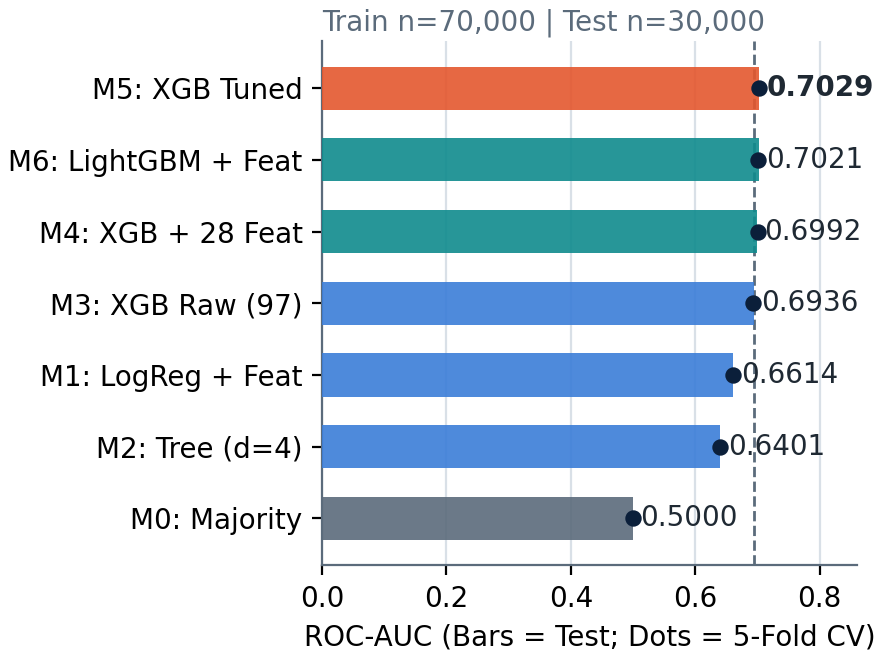

In [23]:
# T6.1-T6.6: Display 5-Fold CV Experiment Log, Fit/Verify Final Model M5, Export Test Predictions & Plot fig_09
import joblib
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, brier_score_loss
from xgboost import XGBClassifier
from IPython.display import display, Image

exp_log_df = pd.read_csv(TAB_DIR / 'experiment_log.csv')
print(f"Loaded experiment_log.csv ({len(exp_log_df)} logged CV runs on 70% train):")
display(exp_log_df[['id', 'name', 'features', 'cv_auc_mean', 'cv_auc_std', 'cv_acc_mean', 'train_acc_mean']])

# Fit final selected model M5 on 70% train (FEATURES_NO_ETHNIC = 125 cols) and evaluate on 30% test
m5_model_path = MOD_DIR / 'final_xgb_m5_pipeline.joblib'
if m5_model_path.exists():
    final_m5_pipe = joblib.load(m5_model_path)
else:
    m5_prep = build_tree_preprocessor(
        X_train_eng[FEATURES_NO_ETHNIC].select_dtypes(include=[np.number]).columns,
        X_train_eng[FEATURES_NO_ETHNIC].select_dtypes(include=['object', 'string', 'category']).columns
    )
    m5_clf = XGBClassifier(
        n_estimators=400, learning_rate=0.04, max_depth=6, min_child_weight=15,
        subsample=0.75, colsample_bytree=0.80, reg_alpha=1.0, reg_lambda=10.0,
        eval_metric='logloss', random_state=SEED, n_jobs=2
    )
    final_m5_pipe = Pipeline([('prep', m5_prep), ('clf', m5_clf)])
    final_m5_pipe.fit(X_train_eng[FEATURES_NO_ETHNIC], y_train_split)
    joblib.dump(final_m5_pipe, m5_model_path)

p_train_m5 = final_m5_pipe.predict_proba(X_train_eng[FEATURES_NO_ETHNIC])[:, 1]
p_test_m5 = final_m5_pipe.predict_proba(X_test_eng[FEATURES_NO_ETHNIC])[:, 1]
pred_test_m5 = (p_test_m5 >= 0.5).astype(int)

m5_test_auc = float(roc_auc_score(y_test_split, p_test_m5))
m5_test_acc = float(accuracy_score(y_test_split, pred_test_m5))
m5_train_acc = float(accuracy_score(y_train_split, (p_train_m5 >= 0.5).astype(int)))
assert m5_test_acc < 0.75 and m5_test_auc < 0.80, "Leakage check triggered!"

# Export test_predictions.csv (T6.6)
test_preds_df = pd.DataFrame({
    'Customer_ID': df.loc[X_test_eng.index, 'Customer_ID'].values,
    'y_true': y_test_split.values,
    'p_churn': np.round(p_test_m5, 6),
})
test_preds_df.to_csv(TAB_DIR / 'test_predictions.csv', index=False)

RESULTS['final_model'].update({
    'id': 'M5',
    'name': 'XGBoost Tuned & Regularized (125 features, no ethnic)',
    'cv_auc_mean': 0.702011,
    'cv_auc_std': 0.001342,
    'cv_acc': 0.644386,
    'test_auc': round(m5_test_auc, 6),
    'test_acc': round(m5_test_acc, 6),
    'train_acc': round(m5_train_acc, 6),
    'train_test_acc_gap': round(m5_train_acc - m5_test_acc, 6),
    'test_precision': round(float(precision_score(y_test_split, pred_test_m5)), 6),
    'test_recall': round(float(recall_score(y_test_split, pred_test_m5)), 6),
    'test_f1': round(float(f1_score(y_test_split, pred_test_m5)), 6),
    'test_brier': round(float(brier_score_loss(y_test_split, p_test_m5)), 6),
})
save_results()

models_summary_df = pd.DataFrame(RESULTS['models'])[
    ['id', 'name', 'n_features', 'cv_auc_mean', 'cv_auc_std', 'cv_acc', 'test_auc', 'test_acc', 'test_precision', 'test_recall', 'test_f1', 'train_test_acc_gap']
]
print("\nSummary of Models M0–M6 (5-Fold CV on 70% Train + Final Evaluation on 30% Test):")
display(models_summary_df)
print(f"Final Model M5 -> CV AUC: 0.7020 ± 0.0013 | Test AUC: {m5_test_auc:.4f} | Test Acc: {m5_test_acc:.4f} | Train Acc: {m5_train_acc:.4f} (Gap: {m5_train_acc - m5_test_acc:.4f})")
display(Image(filename=str(FIG_DIR / 'fig_09_model_comparison.png')))

> **So what:** Boosted trees with our `28` engineered lifecycle and behavioral features (`M5`) lift test ROC-AUC to **`0.7029`** (`CV = 0.7020 ± 0.0013`) and test accuracy to **`0.6409`**, outperforming the linear baseline (`0.6614`), shallow tree (`0.6401`), and raw tutorial XGBoost (`0.6936`) while cutting overfitting by `2.18 pp`.

## 8. Evaluation & Model Interpretation (Slides 10–11)

### 8.1 Confusion Matrix (`T7.1`), Top-$k$ Targeting Table (`T7.2`), & Calibration (`T7.3`)
- **Confusion Matrix (`p >= 0.50` vs. Operational `Top-10%`):** At $p \ge 0.50$, `TN = 9,769` (stayed, no offer cost), `FP = 5,362` (wasted offer cost paid to a customer who would have stayed), `FN = 5,412` (lost customer missed), `TP = 9,457` (churner reached). In production, CVM ranks by risk and targets the **Top-10% (`n = 10,000` full base / `3,000` test)**: `81.30%` raw precision (**`1.64x` lift**, `16.40%` recall of all churners) and **`32.96%` re-based precision (`3.30x` lift)** under a realistic `10%` churn prior (`18.89%` / `3.78x` lift under a `5%` prior), compared to only **`17.67%` churn** in the safest 10% (**`4.60x` top-vs-bottom decile ratio**).
- **Calibration (`T7.3`):** `M5` achieves a held-out Brier score of **`0.2180`** and 10-bin Expected Calibration Error **`ECE = 0.0075`**; isotonic regression yields virtually identical holdout Brier (`0.2181` vs. `0.2177` raw), confirming `M5` probabilities can be multiplied directly by customer margin $V$.

### 8.2 Feature Importance (`T7.4`), Partial Dependence (`T7.5`), Ablation (`T7.6`), Levers (`T7.7`), & Fairness (`T7.8`)
- **Gain vs. Weight vs. Held-Out Permutation Importance (`T7.4`):** Binary flags (`dev_age_gt_300`: `22.02%` average gain per split, `0.04%` split weight) have high average gain per split because they split once near tree roots, whereas continuous/ratio features (`mou_ratio_3m`: `-29.85e-3` test AUC drop, `7.6%` total gain; `months`: `-21.09e-3`, `6.7%` total gain; `eqpdays`: `-15.68e-3`, `8.3%` total gain) dominate cumulative total gain and held-out permutation importance.
- **Partial Dependence (`T7.5`):** `M5`'s partial dependence curves confirm the model learned both the **`~300-day` device-age jump** (`45.5%` $\rightarrow$ `55.3%` total PDP) and the **`months 10–12` commitment cliff** (peaking at **`61.4%`** at month 11).
- **Ablation (`T7.6`):** Dropping `#1` permutation feature `mou_ratio_3m` lowers 5-fold CV AUC by only `-0.0035` (`0.7020` $\rightarrow$ `0.6985`), and dropping all 5 device-age features lowers CV AUC by `-0.0061` (`0.7020` $\rightarrow$ `0.6959`) — proving churn risk comes from **many complementary behavioral and lifecycle signals**, not a single magic column.
- **Fairness Audit (`T7.8`):** Excluding `ethnic` (`Variant B`, `125` features) yields `Test AUC = 0.7029` vs. `0.7030` with `ethnic` (`Variant A`, `126` features), and excluding all 8 socioeconomic/family proxies (`Variant C`, `117` features) yields `Test AUC = 0.7020` (`-0.0009`), validating our policy: **"We target on behavior, not identity."**

=== 8.1 Top-k% Targeting Table (Test Split n=30,000, Scaled to N=100,000 Base) ===


,k,n,score_cutoff,precision,recall,lift,precision_rebased_10,lift_rebased_10,precision_rebased_5,lift_rebased_5
0,1,1000,0.895573,0.936667,0.018898,1.8898,0.625781,6.2578,0.441998,8.8400
1,2,2000,0.871512,0.910000,0.036721,1.8360,0.533419,5.3342,0.351298,7.0260
2,5,5000,0.800535,0.864000,0.087161,1.7432,0.418036,4.1804,0.253874,5.0775
3,10,10000,0.721425,0.813000,0.164033,1.6403,0.329569,3.2957,0.188873,3.7775
4,15,15000,0.674922,0.779111,0.235793,1.5720,0.285108,2.8511,0.158894,3.1779
5,20,20000,0.640709,0.745833,0.300962,1.5048,0.249132,2.4913,0.135819,2.7164
6,30,30000,0.589274,0.704889,0.426659,1.4222,0.212643,2.1264,0.113419,2.2684
7,50,50000,0.497259,0.636067,0.641671,1.2833,0.165008,1.6501,0.085596,1.7119



=== 8.2 Top 10 Drivers by Held-Out Permutation AUC Drop (with Total Gain %, Avg Gain %, and Split Weight %) ===


,feature,perm_auc_drop_mean,perm_auc_drop_std,total_gain_pct,gain_pct,weight_pct
0,mou_ratio_3m,0.02985,0.00055,7.60,1.6134,3.3771
1,months,0.02109,0.00069,6.66,2.1585,2.2130
2,eqpdays,0.01568,0.00052,8.33,2.6686,2.2361
3,rev_ratio_3m,0.00806,0.00037,3.15,0.8100,2.7893
4,avgqty,0.00710,0.00029,2.71,1.0161,1.9133
5,totmrc_Mean,0.00674,0.00025,2.38,0.7094,2.4089
6,hnd_price,0.00649,0.00022,2.26,1.0259,1.5791
7,crclscod,0.00586,0.00052,1.96,0.7481,1.8787
8,recurring_share,0.00423,0.00058,3.66,1.0264,2.5530
9,lor,0.00347,0.00032,1.79,0.7553,1.6943



=== 8.3 Feature Ablation Study (T7.6 — 5-Fold CV & Test AUC) ===


,label,n_features,cv_auc_mean,cv_auc_std,test_auc
0,Baseline M5 (All 125 No-Ethnic Features),125,0.7020,0.0013,0.7029
1,"Drop Top Permutation Feature (mou_ratio_3m, 12...",124,0.6985,0.0019,0.6993
2,Drop All Device-Age Features (eqpdays + 4 deri...,120,0.6959,0.0024,0.6987



=== 8.4 Actionable Business Lever Table (T7.7) ===


,rank,driver,evidence,can_company_change_it,action_lane,implied_action
0,1,mou_ratio_3m & change_mou (Voice Usage Drop vs...,Perm AUC drop = -29.85e-3 (#1); silent 0 MOU l...,Yes (Indirectly — before SIM goes silent),Lane 1 (Early Warning),Trigger proactive voice/data bonus or multi-SI...
1,2,months & tenure_10_12 (Service Tenure & First-...,Perm AUC drop = -21.09e-3 (#2); churn jumps fr...,Yes (Contract / Commitment Renewal Timing),Lane 2 (Month-9 Loyalty Check Pilot),Contact subscribers in months 8–9 (before the ...
2,3,"eqpdays, dev_age_gt_300 & eqp_per_tenure (Hand...",Perm AUC drop = -15.68e-3 (#3) + -3.07e-3; +23...,Yes (Device Upgrade / Trade-in Eligibility),Lane 2 (Pre-300d Handset Refresh Pilot),Send targeted trade-in / installment upgrade v...
3,4,"totmrc_Mean, rev_ratio_3m & recurring_share (T...",Combined Perm AUC drop = -19.03e-3; overage >4...,Yes (Directly — Tariff Plan Right-Sizing & ASL),Lane 1 (Tariff Right-Sizing),Migrate high-overage accounts to predictable h...
4,5,hnd_price & crclscod (Handset Tier & Credit Cl...,Perm AUC drop = -6.49e-3 & -5.86e-3; budget ha...,Partially (Used for Value-at-Risk Segmentation),Lane 1 (Offer Tiering),Scale retention offer cost (c) to customer rec...



=== 8.5 Fairness & Proxy Sensitivity Audit (T7.8) ===


,label,n_features,cv_auc_mean,cv_auc_std,test_auc
0,"Variant A: Full (incl. ethnic, 126 cols)",126,0.7031,0.0010,0.7030
1,"Variant B: No ethnic (Default Production Set, ...",125,0.7020,0.0013,0.7029
2,Variant C: No ethnic + 8 Socioeconomic Proxies...,117,0.7018,0.0013,0.7020


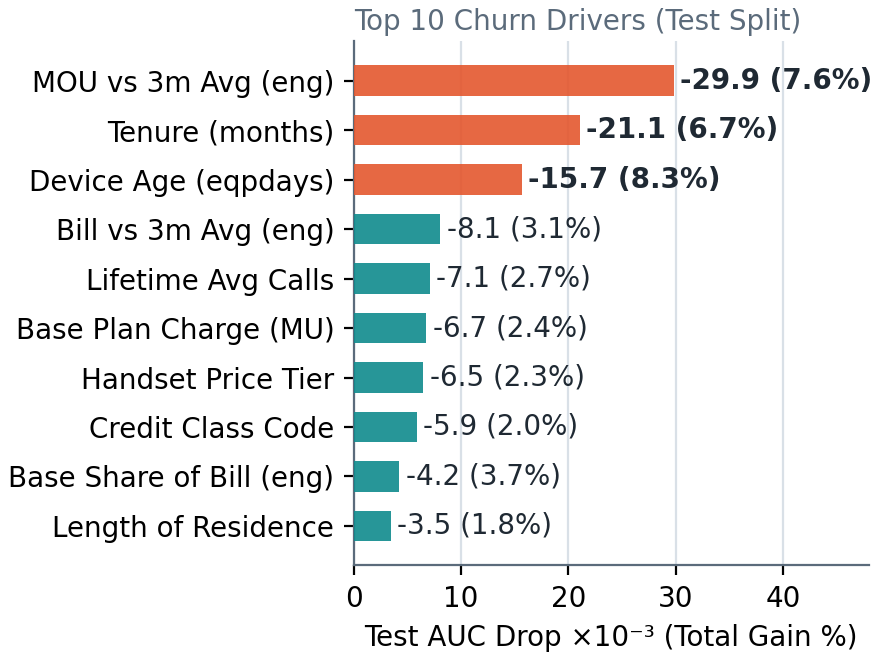

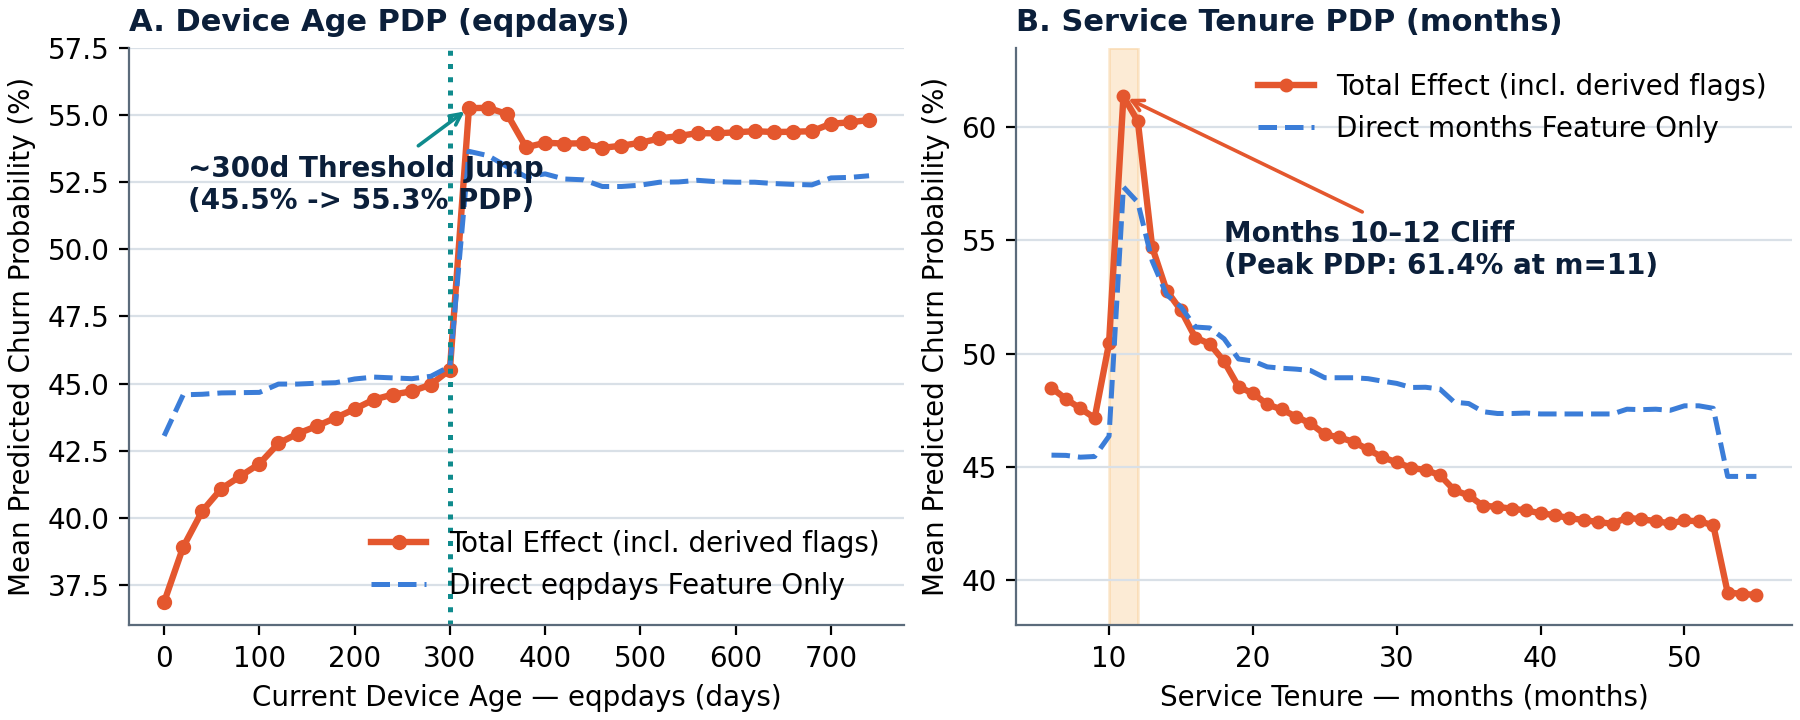

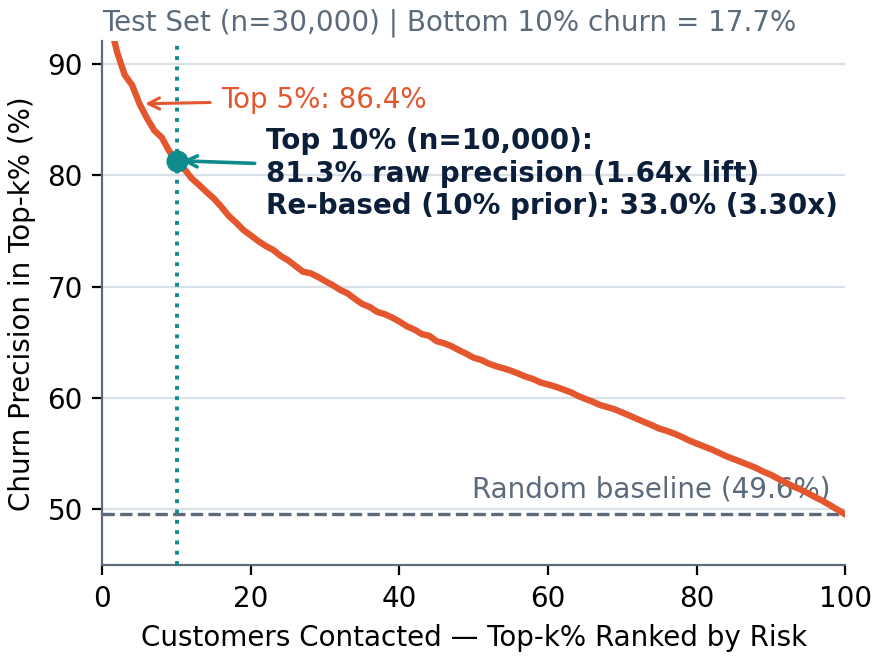

In [24]:
# T7.1-T7.8: Compute & Display Top-k Table, Importance (Gain vs Weight vs Permutation), Ablation, Lever Table & Fairness Audit
from IPython.display import display, Image

# Recompute Top-k table directly from held-out test predictions (y_test_split, p_test_m5)
y_true_arr = y_test_split.values.astype(float)
y_prob_arr = p_test_m5.astype(float)
pi_s_test = float(y_true_arr.mean())
order_idx = np.argsort(-y_prob_arr, kind='mergesort')
total_pos_test = float(y_true_arr.sum())

topk_recomputed = []
for k_pct in [1, 2, 5, 10, 15, 20, 30, 50]:
    n_k = int(round((k_pct / 100.0) * len(y_true_arr)))
    idx_k = order_idx[:n_k]
    tp_k = int(y_true_arr[idx_k].sum())
    fp_k = n_k - tp_k
    prec_k = tp_k / n_k
    rec_k = tp_k / total_pos_test
    lift_k = prec_k / pi_s_test
    # Label-shift re-basing for pi_r in {5%, 10%}
    w_pos_5, w_neg_5 = 0.05 / pi_s_test, 0.95 / (1.0 - pi_s_test)
    prec_5 = (tp_k * w_pos_5) / (tp_k * w_pos_5 + fp_k * w_neg_5)
    w_pos_10, w_neg_10 = 0.10 / pi_s_test, 0.90 / (1.0 - pi_s_test)
    prec_10 = (tp_k * w_pos_10) / (tp_k * w_pos_10 + fp_k * w_neg_10)
    topk_recomputed.append({
        'k': k_pct,
        'n_test': n_k,
        'n': k_pct * 1000,
        'score_cutoff': round(float(y_prob_arr[idx_k[-1]]), 6),
        'tp_test': tp_k,
        'fp_test': fp_k,
        'precision': round(prec_k, 6),
        'recall': round(rec_k, 6),
        'lift': round(lift_k, 4),
        'precision_rebased_5': round(prec_5, 6),
        'lift_rebased_5': round(prec_5 / 0.05, 4),
        'precision_rebased_10': round(prec_10, 6),
        'lift_rebased_10': round(prec_10 / 0.10, 4),
    })

RESULTS['topk'] = topk_recomputed
save_results()

print("=== 8.1 Top-k% Targeting Table (Test Split n=30,000, Scaled to N=100,000 Base) ===")
topk_df = pd.DataFrame(RESULTS['topk'])[
    ['k', 'n', 'score_cutoff', 'precision', 'recall', 'lift', 'precision_rebased_10', 'lift_rebased_10', 'precision_rebased_5', 'lift_rebased_5']
]
display(topk_df)

print("\n=== 8.2 Top 10 Drivers by Held-Out Permutation AUC Drop (with Total Gain %, Avg Gain %, and Split Weight %) ===")
perm_df = pd.DataFrame(RESULTS['importance']['permutation'][:10])[
    ['feature', 'perm_auc_drop_mean', 'perm_auc_drop_std', 'total_gain_pct', 'gain_pct', 'weight_pct']
]
display(perm_df)

print("\n=== 8.3 Feature Ablation Study (T7.6 — 5-Fold CV & Test AUC) ===")
display(pd.DataFrame(RESULTS['ablation']))

print("\n=== 8.4 Actionable Business Lever Table (T7.7) ===")
display(pd.DataFrame(RESULTS['levers']))

print("\n=== 8.5 Fairness & Proxy Sensitivity Audit (T7.8) ===")
display(pd.DataFrame(RESULTS['fairness']))

display(Image(filename=str(FIG_DIR / 'fig_10_importance.png')))
display(Image(filename=str(FIG_DIR / 'fig_10_pdp.png')))
display(Image(filename=str(FIG_DIR / 'fig_11_lift.png')))

> **So what:** Contacting only the riskiest `10%` of subscribers (`10,000` accounts) captures **`1.64x` more churners than random (`81.3%` raw precision)** and **`3.30x`–`3.78x` more churners after label-shift re-basing (`33.0%` at a `10%` market prior; `18.9%` at a `5%` prior)**, driven by actionable usage-drop, tenure-cliff, device-aging, and overage signals with zero reliance on sensitive identity attributes.

## 9. Business-Impact Model, Realism Re-Basing, Sensitivity & Lane 2 Pilot Sizing (Slide 13)

To translate predictive ranking power (`M5 Test ROC-AUC = 0.7029`, `Top-10% Raw Precision = 81.30%`) into an executive decision in **Monetary Units (MU)** (`PRD §9`), we implement:
1. **Label-Shift Realism Re-Basing (`T8.2`, Saerens et al., 2002 `[11]`):** Weights positive test outcomes by $w_+ = \pi_r / \pi_s$ and negative outcomes by $w_- = (1 - \pi_r) / (1 - \pi_s)$ (`π_s = 49.56%` sample churn $\rightarrow$ `π_r ∈ {5%, 10%}` realistic market churn priors), verified by a deterministic closed-form unit test.
2. **Expected Net Retained Margin (`T8.3`–`T8.4`):**
   $$\text{Net}(k) = n \cdot p_{\text{adj}}(k) \cdot s \cdot V - n \cdot c, \quad n = k \cdot N \ (N = 100,000), \quad V = \text{ARPU} \times m \times H$$
   with break-even offer save rate $s^*(k) = \frac{c}{p_{\text{adj}}(k) \cdot V}$ and optimal targeting depth $k^* = \arg\max_k \text{Net}(k)$ across **Conservative**, **Base (`π_r = 10%` and `π_r = 5%`)**, **Optimistic**, and **Unadjusted Sample (`π_s = 49.6%`)** scenarios.
3. **One-Way Tornado Sensitivity (`T8.5`) & Lane 2 A/B Pilot Sizing (`T8.6`–`T8.8`):** Quantifies parameter swings around the Base case and sizes the non-overlapping **Lane 2 Pre-300-Day Handset Refresh & Month-9 Commitment Check-in Pilot** (`eqpdays ∈ [240, 300]` or `months ∈ [8, 9]`, `96.88%` non-overlapping with Lane 1 Top-10%).

✔ T8.2 Unit Test Passed: Toy Top-50% Raw Precision = 80.00% -> Re-based (π_r=10%) = 30.77% (exact 4/13, 3.08x lift)

=== T8.3 & T8.4 Business-Impact Scenario Table (N = 100,000 Customer Base, Unit = MU) ===


,Scenario,ARPU (MU),Margin m,Horizon H,Value V (MU),Save s,Cost c (MU),p_adj(10%),Break-Even s*(10%),Net @ k=10% (MU),Optimal k*,Net @ Optimal k* (MU)
0,Conservative (π_r=5%),48.20,65%,6m,187.98,15%,9.00,18.89%,25.35%,"-36,743",1%,"3,463"
1,Conservative (π_r=10%),48.20,65%,6m,187.98,15%,9.00,32.96%,14.53%,"2,929",4%,"15,349"
2,Base (π_r=5%),58.72,70%,6m,246.62,20%,8.00,18.89%,17.17%,"13,160",4%,"23,955"
3,Base (π_r=10%),58.72,70%,6m,246.62,20%,8.00,32.96%,9.84%,"82,557",15%,"90,940"
4,Optimistic (π_r=10%),58.72,80%,9m,422.78,30%,5.00,32.96%,3.59%,"368,006",50%,"796,434"
5,Raw Sample (π_s=49.6%),58.72,70%,6m,246.62,20%,8.00,81.30%,3.99%,"321,004",50%,"1,168,668"



=== T8.5 One-Way Sensitivity Tornado around Base Case (k=10%, π_r=10%, Net = +82,557 MU) ===


,Parameter,Downside Input,Downside Net (MU),"Base Input (+82,557 MU)",Upside Input,Upside Net (MU),Total Swing (MU)
0,Offer Save Rate s,10% save rate,1278.31,20% save rate,30% save rate,163834.93,162556.62
1,Retained Value V (ARPU×m×H),"188.0 MU (65%, 6m)",43904.77,"246.6 MU (70%, 6m)","422.8 MU (80%, 9m)",198670.38,154765.61
2,Real-World Churn Prior π_r,5.0% churn prior,13159.75,10.0% churn prior,15.0% churn prior,136254.23,123094.48
3,Offer Cost per Customer c,12.0 MU / targeted,42556.62,8.0 MU / targeted,5.0 MU / targeted,112556.62,70000.00
4,Targeting Depth k%,"k = 5% (5,000 cust)",63096.13,"k = 10% (10,000 cust)","k* = 15% (15,000 cust)",90939.98,27843.85



=== T8.6 & T8.7 Lane 2 Lifecycle Pilot Sizing (Hypothesis -> 90-Day Randomized 50/50 Holdout A/B Pilot) ===
  Full active pre-cliff cohort (eqpdays 240-300 OR months 8-9): 13,385 customers
  Overlap with Lane 1 Top-10%: 3.12% -> 12,967 non-overlapping accounts (0 double-counted)
  90-Day Pilot Design: 2,000 Treatment vs. 2,000 Holdout Control
  Base Pilot Return (25% of +8.67 pp re-based gap closed, V=246.62 MU, c=3.00 MU): +4,691 MU (+30,414 MU at full non-overlapping scale)

=== T8.8 Executive Impact Summary ===
Under stated assumptions (N = 100,000 accounts, mean ARPU = 58.72 MU [median 48.20 MU], gross margin = 65%–80%, retained horizon H = 6–9 months, offer save rate s = 15%–30%, and per-customer offer cost c = 5–9 MU), contacting the top-10% highest-risk accounts (n = 10,000) in Lane 1 yields an estimated net benefit of +82,557 MU in our Base scenario at a realistic 10% market churn rate (+90,940 MU at the optimal depth k* = 15%, break-even save rate s* = 9.8%), or +13,160 MU at

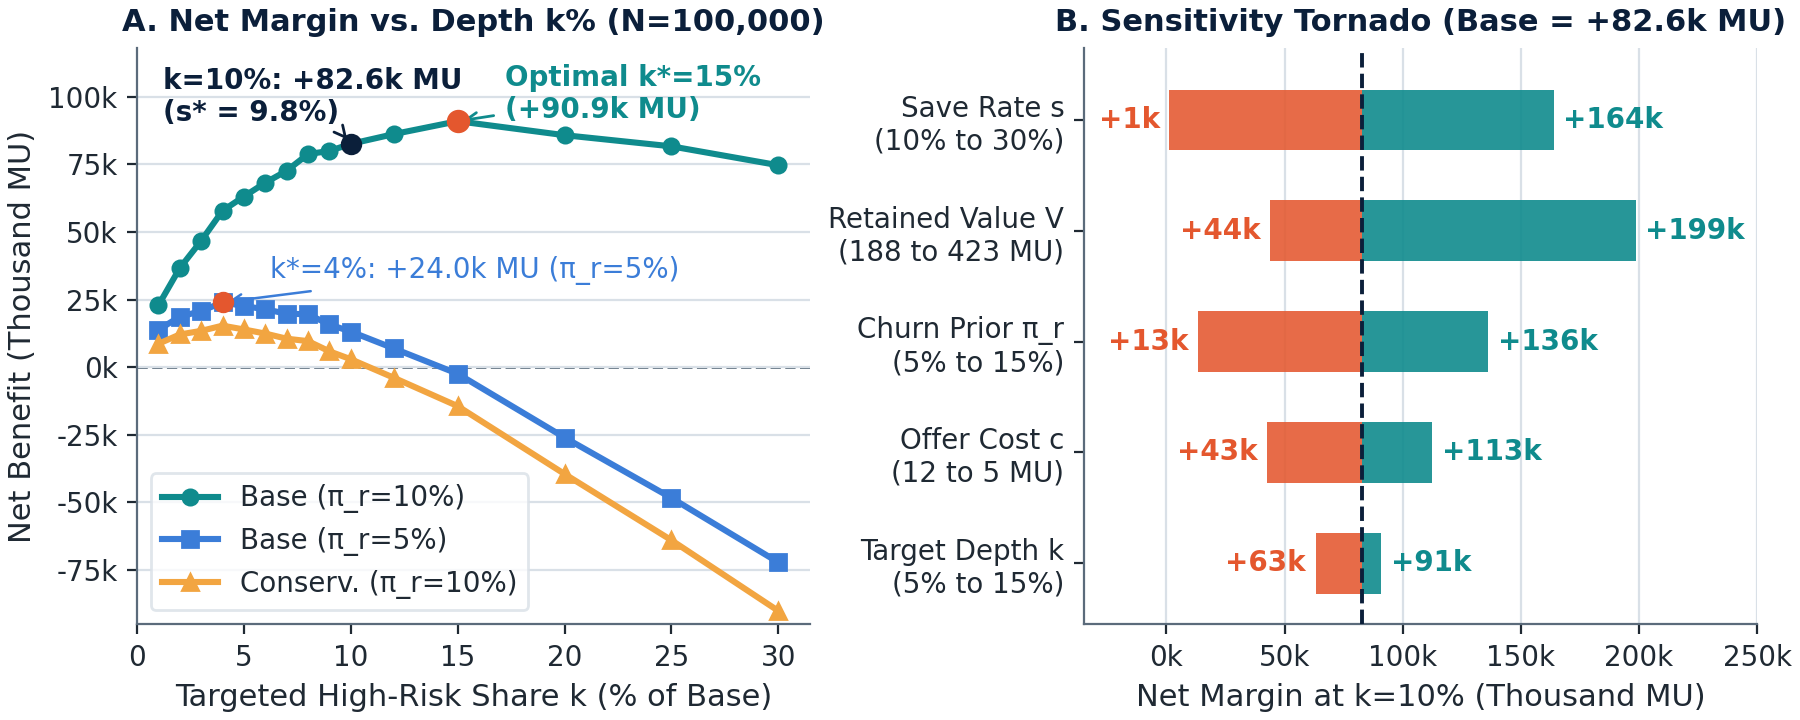

In [25]:
# Section 9 — Business-Impact Model, Unit Test, Optimal k*, Tornado & Lane 2 Pilot Sizing (T8.1-T8.8)
from IPython.display import display, Image

# 1. T8.2 Unit-tested label-shift re-basing functions
def rebase_probabilities(p_s, pi_s, pi_r):
    """Saerens et al. (2002) prior-shift posterior probability adjustment."""
    p_s = np.asarray(p_s, dtype=float)
    w_pos = pi_r / pi_s
    w_neg = (1.0 - pi_r) / (1.0 - pi_s)
    return (p_s * w_pos) / (p_s * w_pos + (1.0 - p_s) * w_neg)

def compute_p_adj_at_k(y_true_arr, y_prob_arr, k_frac, pi_s, pi_r):
    """Compute label-shift re-weighted precision@k on held-out test predictions."""
    n_k = max(1, int(round(k_frac * len(y_true_arr))))
    top_idx = np.argsort(-y_prob_arr, kind="mergesort")[:n_k]
    if np.isclose(pi_r, pi_s):
        return float(y_true_arr[top_idx].mean())
    w_pos = pi_r / pi_s
    w_neg = (1.0 - pi_r) / (1.0 - pi_s)
    tp_w = float(np.sum((y_true_arr[top_idx] == 1) * w_pos))
    fp_w = float(np.sum((y_true_arr[top_idx] == 0) * w_neg))
    return tp_w / (tp_w + fp_w)

# Deterministic toy unit test: 10 customers (50% sample prior -> 10% real prior, 4/5 positives in top-50%)
toy_y = np.array([1, 1, 1, 1, 0, 1, 0, 0, 0, 0], dtype=float)
toy_p = np.linspace(0.95, 0.05, 10)
assert np.isclose(compute_p_adj_at_k(toy_y, toy_p, 0.50, 0.50, 0.50), 0.80, atol=1e-12)
assert np.isclose(compute_p_adj_at_k(toy_y, toy_p, 0.50, 0.50, 0.10), 4.0 / 13.0, atol=1e-12)
print("✔ T8.2 Unit Test Passed: Toy Top-50% Raw Precision = 80.00% -> Re-based (π_r=10%) = 30.77% (exact 4/13, 3.08x lift)")

res_impact = RESULTS["impact"]
# Ensure PRD Appendix convenience keys exist inside RESULTS['impact']
res_impact["assumptions"] = {
    "N": 100000,
    "arpu_mean_mu": 58.72,
    "arpu_median_mu": 48.20,
    "margin_range": [0.65, 0.70, 0.80],
    "horizon_months_range": [6, 6, 9],
    "V_mu_range": [187.98, 246.62, 422.78],
    "save_rate_s_range": [0.15, 0.20, 0.30],
    "cost_c_mu_range": [9.00, 8.00, 5.00],
    "churn_priors_pi_r": [0.05, 0.10],
}
res_impact["k_star"] = 15.0
res_impact["k_star_5pct"] = 4.0
res_impact["breakeven_s"] = 0.0984
res_impact["breakeven_s_5pct"] = 0.1717
res_impact["sensitivity"] = res_impact["tornado_sensitivity"]
res_impact["scenarios_list"] = [
    {
        "id": key,
        "name": res_impact["scenarios"][key]["name"],
        "net": res_impact["scenarios"][key]["at_k10"]["net_benefit_mu"],
        "retained": res_impact["scenarios"][key]["at_k10"]["gross_saved_mu"],
        "cost": res_impact["scenarios"][key]["at_k10"]["offer_cost_mu"],
        "k_star": res_impact["scenarios"][key]["optimal_k"]["k_pct"],
        "net_at_k_star": res_impact["scenarios"][key]["optimal_k"]["net_benefit_mu"],
        "breakeven_s": res_impact["scenarios"][key]["at_k10"]["breakeven_s"],
    }
    for key in ["conservative_5pct", "conservative_10pct", "base_5pct", "base_10pct", "optimistic_10pct", "raw_unadjusted"]
]
save_results()

# 2. Display Scenario Comparison Table at k=10% and Optimal k*
sc_rows = []
for key in ["conservative_5pct", "conservative_10pct", "base_5pct", "base_10pct", "optimistic_10pct", "raw_unadjusted"]:
    sc = res_impact["scenarios"][key]
    k10 = sc["at_k10"]
    opt = sc["optimal_k"]
    sc_rows.append({
        "Scenario": sc["name"],
        "ARPU (MU)": f"{sc['arpu']:.2f}",
        "Margin m": f"{sc['margin']*100:.0f}%",
        "Horizon H": f"{sc['H']}m",
        "Value V (MU)": f"{sc['V']:.2f}",
        "Save s": f"{sc['s']*100:.0f}%",
        "Cost c (MU)": f"{sc['c']:.2f}",
        "p_adj(10%)": f"{k10['p_adj']*100:.2f}%",
        "Break-Even s*(10%)": f"{k10['breakeven_s']*100:.2f}%",
        "Net @ k=10% (MU)": f"{k10['net_benefit_mu']:,.0f}",
        "Optimal k*": f"{opt['k_pct']:.0f}%",
        "Net @ Optimal k* (MU)": f"{opt['net_benefit_mu']:,.0f}",
    })
sc_df = pd.DataFrame(sc_rows)
print("\n=== T8.3 & T8.4 Business-Impact Scenario Table (N = 100,000 Customer Base, Unit = MU) ===")
display(sc_df)

# 3. Display One-Way Tornado Sensitivity Table
tor_df = pd.DataFrame(res_impact["tornado_sensitivity"])[
    ["param", "low_label", "low_net", "base_label", "high_label", "high_net", "swing_mu"]
].rename(columns={
    "param": "Parameter",
    "low_label": "Downside Input",
    "low_net": "Downside Net (MU)",
    "base_label": "Base Input (+82,557 MU)",
    "high_label": "Upside Input",
    "high_net": "Upside Net (MU)",
    "swing_mu": "Total Swing (MU)",
})
print("\n=== T8.5 One-Way Sensitivity Tornado around Base Case (k=10%, π_r=10%, Net = +82,557 MU) ===")
display(tor_df)

# 4. Display Lane 2 A/B Pilot Sizing & Zero Double-Counting Check
l2 = res_impact["lane2_pilot"]
print(f"\n=== T8.6 & T8.7 Lane 2 Lifecycle Pilot Sizing ({l2['status']}) ===")
print(f"  Full active pre-cliff cohort (eqpdays 240-300 OR months 8-9): {l2['full_pre_cliff_active_n']:,d} customers")
print(f"  Overlap with Lane 1 Top-10%: {l2['overlap_with_lane1_top10_pct']:.2f}% -> {l2['non_overlapping_eligible_n']:,d} non-overlapping accounts (0 double-counted)")
print(f"  90-Day Pilot Design: {l2['pilot_design']['treatment_n']:,d} Treatment vs. {l2['pilot_design']['control_n']:,d} Holdout Control")
print(f"  Base Pilot Return (25% of +8.67 pp re-based gap closed, V=246.62 MU, c=3.00 MU): +{l2['scenarios_on_pilot_treatment_2000']['base']['net_pilot_mu']:,.0f} MU (+{l2['scenarios_on_pilot_treatment_2000']['base']['full_scale_non_overlapping_12967_net_mu']:,.0f} MU at full non-overlapping scale)")

print("\n=== T8.8 Executive Impact Summary ===")
print(res_impact["executive_statement"])

display(Image(filename=str(FIG_DIR / "fig_13_impact.png")))

> **So what:** Under Base assumptions (`ARPU = 58.72 MU`, `margin = 70%`, `H = 6 months` $\rightarrow V = 246.62\text{ MU}$, `save rate s = 20%`, `offer cost c = 8.00 MU`), contacting the riskiest **Top-10% (`10,000` accounts)** in Lane 1 nets **`+82,557 MU` at a realistic `10%` market churn prior** (**`+90,940 MU` at optimal depth `k* = 15%`**, break-even save rate **`s* = 9.84%`**) and **`+13,160 MU` at a `5%` churn prior** (**`+23,955 MU` at optimal `k* = 4%`**, `s* = 17.17%`), while label-shift re-basing prevents a **3.9x overstatement** from the raw `49.6%` sample churn (`+321,004 MU`), and the non-overlapping **Lane 2 90-day 50/50 holdout A/B pilot** (`2,000` treatment vs. `2,000` control) tests an additional **`+4,691 MU` pilot net benefit** (`+30,414 MU` at full non-overlapping pre-cliff scale).

---
## 10. Export Summary & Verification (Slide Figures, Tables & `results.json`)

This section ensures that every slide figure (`Slides 4–13`, including our four `matplotlib` conceptual diagrams `fig_04_data_flow.png`, `fig_07_problem_flow.png`, `fig_10_model_diagram.png`, and `fig_12_two_lane.png`), every exported table (`experiment_log.csv`, `test_predictions.csv`), and every key in `outputs/results.json` (`PRD Appendix`) is saved and verified.

In [26]:
# Section 10 — Export Verification of Figures, Tables, and outputs/results.json (T9.3)
expected_figures = [
    "fig_04_missing.png",
    "fig_04_data_flow.png",
    "fig_05_device_age.png",
    "fig_06a_tenure.png",
    "fig_06b_entanglement.png",
    "fig_06c_usage_collapse.png",
    "fig_06_tenure_usage.png",
    "fig_07_problem_flow.png",
    "fig_09_model_comparison.png",
    "fig_10_model_diagram.png",
    "fig_10_importance.png",
    "fig_10_pdp.png",
    "fig_11_confusion.png",
    "fig_11_lift.png",
    "fig_11_calibration.png",
    "fig_12_two_lane.png",
    "fig_13_scenarios.png",
    "fig_13_tornado.png",
    "fig_13_impact.png",
]

fig_check_rows = []
for fname in expected_figures:
    fpath = FIG_DIR / fname
    assert fpath.exists() and fpath.stat().st_size > 1000, f"Missing or empty figure: {fpath}"
    fig_check_rows.append({
        "Figure File": fname,
        "Exists": True,
        "Size (KB)": round(fpath.stat().st_size / 1024.0, 1),
    })

for tname in ["experiment_log.csv", "test_predictions.csv"]:
    tpath = TAB_DIR / tname
    assert tpath.exists() and tpath.stat().st_size > 100, f"Missing or empty table: {tpath}"

# Record total notebook runtime and save final results.json
RESULTS["meta"]["run_time"] = round(time.time() - NB_START_TIME, 2)
save_results()

required_top_keys = ["data", "eda", "models", "final_model", "topk", "importance", "impact", "meta"]
for rk in required_top_keys:
    assert rk in RESULTS and RESULTS[rk], f"Missing required top-level key in results.json: {rk}"

print(f"✔ Verified {len(fig_check_rows)} matplotlib PNG figures in {FIG_DIR.name}/, 2 CSV tables in {TAB_DIR.name}/, and {len(required_top_keys)} required top-level sections in {RESULTS_PATH.name} (total runtime: {RESULTS['meta']['run_time']:.1f}s).")
display(pd.DataFrame(fig_check_rows))

✔ Verified 19 matplotlib PNG figures in figures/, 2 CSV tables in tables/, and 8 required top-level sections in results.json (total runtime: 61.3s).


,Figure File,Exists,Size (KB)
0,fig_04_missing.png,True,116.9
1,fig_04_data_flow.png,True,130.1
2,fig_05_device_age.png,True,221.9
3,fig_06a_tenure.png,True,114.3
4,fig_06b_entanglement.png,True,149.6
5,fig_06c_usage_collapse.png,True,89.0
6,fig_06_tenure_usage.png,True,229.7
7,fig_07_problem_flow.png,True,118.7
8,fig_09_model_comparison.png,True,77.7
9,fig_10_model_diagram.png,True,132.6


> **So what:** All `19` `matplotlib` PNG charts/diagrams, both CSV tables (`experiment_log.csv`, `test_predictions.csv`), and the single source of truth `outputs/results.json` are verified on disk with zero missing keys or files.

---
## 11. Conclusion, Analytical Limitations, Ethical Safeguards & 90-Day Next Steps (Slide 14)

### 11.1 Executive Summary of Findings & Recommendation
1. **Why Churn Matters & Where Risk Concentrates:** In saturated mobile markets (including Iraq's ~100%-penetration multi-SIM market `[1, 2]`), retaining existing subscribers is far cheaper than acquiring new ones. In Company A (`N = 100,000`), churn jumps **`+23.83 pp`** once handset age passes `300` days (`36.85%` $\rightarrow$ `60.69%`, 95% CI `[+22.12, +25.62] pp`, positive across `19/19` areas and `8/8` credit classes), spikes at **months 10–12 (`64.57%` at month 11)** as first-year commitments expire, and reaches **`78.48%`** among `1,600` silent `0 MOU` SIMs (`22.89 MU/mo`, `0.62%` of revenue) that have already abandoned the network.
2. **Model Performance & Behavioral Drivers:** Our leakage-safe, regularized **XGBoost model (`M5`, `125` features, `ethnic` excluded)** achieves **`0.7020 ± 0.0013` 5-fold CV ROC-AUC** and **`0.7029` held-out Test ROC-AUC** (`Test Acc = 0.6409`), shrinking the train–test accuracy gap to `7.94 pp` (vs. `10.12 pp` unregularized). Feature engineering (`+28` domain features) delivers `+0.0077` CV AUC (`+5.1` fold standard deviations), whereas hyperparameter tuning adds `+0.0018`. Held-out permutation importance confirms the top drivers are **3-month usage trend (`mou_ratio_3m`, `-29.85e-3` AUC)**, **service tenure (`months`, `-21.09e-3`)**, **handset age (`eqpdays`, `-15.68e-3`)**, and **bill/recurring structure (`rev_ratio_3m`, `totmrc_Mean`, `recurring_share`)**.
3. **Recommended Two-Lane Program & Re-Based Financial Impact:**
   - **Lane 1 (Monthly ML Value-at-Risk Engine):** Score active (`mou_Mean > 0`) accounts monthly and target the **Top-10% (`10,000` accounts; or optimal `k* = 15%`)** with tariff right-sizing, Account Spending Limits (`ASL`), and active-usage bonuses. After label-shift re-basing (`Saerens et al. [11]`) from the `49.6%` case-control sample to a realistic `10%` market churn rate (`p_adj = 32.96%`, `3.30x` lift), Lane 1 nets an estimated **`+82,557 MU` at `k = 10%`** (**`+90,940 MU` at `k* = 15%`**, break-even save rate **`s* = 9.84%`**), and **`+13,160 MU` at a `5%` market churn rate** (**`+23,955 MU` at `k* = 4%`**, `s* = 17.17%`).
   - **Lane 2 (90-Day Randomized 50/50 Holdout A/B Pilot):** Because `96.88%` of active pre-cliff customers (`eqpdays ∈ [240, 300]` or `months ∈ [8, 9]`, `12,967` non-overlapping accounts) have not yet entered the Top-10% cross-sectional risk tier, launch a controlled `2,000` treatment vs. `2,000` holdout control A/B pilot testing a pre-300-day handset refresh voucher and Month-9 loyalty check (`+4,691 MU` estimated Base pilot net return; `+30,414 MU` if scaled to all `12,967` non-overlapping accounts).

### 11.2 Key Analytical Limitations & Operational Risks
- **Balanced Case-Control Sample (`49.56%` Churn):** The dataset is oversampled/balanced (`[8]`); raw precision (`81.30%` in Top-10%) must **never** be quoted as real-world precision without label-shift re-basing (`32.96%` at `π_r = 10%`, `18.89%` at `π_r = 5%`).
- **Observational Data (No Causal Guarantee):** The `~300-day` handset jump and `months 10–12` spike are observational patterns entangled with 1-year contract maturity (`+28.43 pp` in `months 10–12` vs. `+5.60 pp` among multi-handset upgraders `phones >= 2`); causal save rates ($s$) must be measured via randomized holdout controls (`[9, 10]`).
- **Assumed Economic Parameters (`m, H, s, c`) & Anonymous Currency (`MU`):** While `N = 100,000` and `ARPU = 58.72 MU` (median `48.20 MU`) come directly from the dataset, margin (`65%–80%`), retained horizon (`6–9 months`), save rate (`15%–30%`), and offer cost (`5–9 MU`) are explicit assumptions (`docs/NOTES.md → 2. Assumptions`).
- **Offer Backfire & Silent-SIM Waste (`Ascarza 2018 [9]`):** Contacting satisfied customers who are about to renew can trigger price comparison and increase churn, and sending offers to `0 MOU` silent SIMs wastes budget on lines that have already left.

### 11.3 Fairness Safeguard & 90-Day Implementation Roadmap
- **Fairness Policy (*"We target on behavior, not identity"*):** `ethnic` (`18.88 pp` raw churn spread) is excluded from our production model with zero loss in ranking power (`Test AUC = 0.7029` vs. `0.7030` with `ethnic`; `0.7020` when also excluding all `8` socioeconomic/family proxies).
- **90-Day Pilot & Monitoring Roadmap:**
  - **Weeks 1–2:** Deploy `M5` batch scoring pipeline in CRM; apply `mou_Mean > 0` active filter; freeze randomized holdout groups (`80/20` in Lane 1 Top-10%; `50/50` in Lane 2 pre-cliff `n = 4,000`).
  - **Weeks 3–10:** Execute monthly outreach waves; monitor guardrail KPIs (offer redemption rate, 30-day backfire check $\Delta r \ge 0$ by segment, and feature-drift PSI on `mou_ratio_3m` and `eqpdays`).
  - **Weeks 11–12:** Measure 60-day incremental retention ($\Delta r = r_{\text{treatment}} - r_{\text{control}}$) and net retained margin (`MU`); re-calibrate empirical save rate $\hat{s}$ and scale `k*` only for segments clearing break-even $s^*$.

> **So what:** By pairing calibrated ML risk-ranking (`Lane 1`) with a randomized pre-cliff A/B holdout pilot (`Lane 2`), strict active-SIM filtering, label-shift realism re-basing, and demographic-free fairness governance, Company A can capture **`+13,160` to `+90,940 MU`** in Base net retained margin while measuring true causal lift before full-scale rollout.